<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

## OBJECTIF DU PROJET avec l'IA
Ce notebook Jupyter constitue la **version 2 (V2) optimisée et auditée** de l'analyse du catalogue produits, des ventes en ligne et de la gestion des stocks pour la société **Bottleneck** (marchand de vins et spiritueux).

Développé dans le cadre du perfectionnement des compétences en Data Analysis et avec l'appui méthodologique de l'IA générative comme partenaire d'audit, ce notebook répond à une triple exigence :
1. **Rigueur technique et analytique** : Correction des erreurs de code, amélioration de la reproductibilité, sécurisation par assertions (`assert`), nettoyage rigoureux et vectorisé des données sans destruction aveugle d'informations.
2. **Posture critique et traçabilité** : Documentation systématique des arbitrages (comparaison V1 vs V2, sensibilité des nettoyages, robustesse statistique des méthodes de détection des outliers).
3. **Valeur métier & Restitution** : Alignement de la terminologie (Pareto / ABC, corrélations de Spearman, analyse des marges HT), visualisation optimisée et préparation des livrables pour la soutenance.

---

### MISSION & LIVRABLES DU PROJET
À l'issue de ce travail, la démarche globale s'articule autour des livrables finaux suivants :
* **Le rapport d'analyse en PDF et Excel** : généré via le script python **rapport_bottleneck.py**
* **Le Notebook Python V2 optimisé** (ce présent document) : Code propre, commenté en français, réorganisé de façon linéaire, paramétré et sécurisé.
* **La documentation méthodologique (Journal des décisions & Comparatifs V1/V2 - Format PDF)** : Synthèse détaillée des prompts, variantes testées, arbitrages techniques, limites identifiées et tableau comparatif d'évaluation.
* **Le portfolio professionnel de compétences** : Présentation du système de veille informationnelle et valorisation des compétences acquises (Data Cleaning, EDA, Data Storytelling, IA Collaborative).

---

### PÉRIMÈTRE DES DONNÉES ÉTUDIÉES
L'analyse croise 3 jeux de données issus des systèmes d'information ERP et E-commerce :
* `erp.xlsx` : Catalogue produits ERP (825 références : prix, stocks, prix d'achat, statut).
* `web.xlsx` : Export E-commerce WordPress / WooCommerce (1 513 lignes d'historique web, fiches produits et ventes).
* `liaison.xlsx` : Table de correspondance technique (`product_id` ERP $\leftrightarrow$ `id_web` / SKU).
* Periode : Concernant les données, c’est une extraction au 31 octobre et pour les ventes c’est du 1 octobre au 31 octobre.


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape  - INSTALLATION DES LIBRAIRIES </h2>
</div>

In [1]:
#Installation de nouvelles Bibliotèques

# !pip install pandera
# !pip install duckdb
# !pip install reportlab xlsxwriter pillow kaleido

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - IMPORT DES LIBRAIRIES </h2>
</div>

In [2]:
# ==============================================================================
# IMPORTS DES BIBLIOTHÈQUES
# ==============================================================================
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Chemins fichiers
import os

# Nouvelles librairies
import duckdb
import pandera.pandas as pa


# Configuration de l'affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
plt.style.use('seaborn-v0_8-whitegrid')

print("✅ Bibliothèques chargées avec succès.")

# Eviter les avertissements
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")


✅ Bibliothèques chargées avec succès.


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - FONCTIONS STANDARDISÉES (MODULES RÉUTILISABLES)</h2>
</div>

In [3]:
#==========================================
# 1) TELECHARGEMENT DU FICHIER EXCEL
#==========================================

def charger_fichier(chemin_fichier: str) -> pd.DataFrame:
    """
    Charge un fichier Excel de manière sécurisée.
    """
    try:
        df = pd.read_excel(chemin_fichier)
        print(f"📄 Fichier '{chemin_fichier}' chargé : {df.shape[0]} lignes, {df.shape[1]} colonnes.")
        return df
    except Exception as e:
        print(f"❌ Erreur lors du chargement de {chemin_fichier} : {e}")
        return None


# =================================================
# 2) LECTURE ET AFFICHAGE DU FICHIER
# =================================================

def lecture_dataframe(df: pd.DataFrame, nom_df: str):
    """
    Affiche le rapport détaillé pour un fichier donné :
    1. Résumé structurel (.info())
    2. Aperçu des 3 premières lignes (sans troncature)
    """
    print("=" * 60)
    print(f" RAPPORT DÉTAILLÉ : {nom_df}")
    print("=" * 60)
    
    # 1. Info du DataFrame
    print("\n[1] Résumé structurel (.info()) :")
    df.info()
    
    # 2. Affichage des 3 premières lignes
    print("\n[2] Aperçu des 3 premières lignes :")
    with pd.option_context('display.max_rows', None, 'display.max_columns', None):
        display(df.head(3))
  
    
#==========================================
# 3) INSPECTION DU FICHIER
#==========================================
    
def inspecter_dataframe(df: pd.DataFrame, nom_df: str) -> dict:
    """
    Analyse un DataFrame et retourne un dictionnaire de synthèse 
    regroupant l'intégrité globale et les statistiques de valeurs manquantes.
    """
    nb_lignes, nb_cols = df.shape
    nb_doublons = df.duplicated().sum()
    
    # Vérifications d'intégrité
    lignes_vides = df.isna().all(axis=1).sum()
    cols_vides = df.isna().all(axis=0).sum()
    
    df_num = df.select_dtypes(include=[np.number])
    lignes_zeros = (df_num == 0).all(axis=1).sum() if not df_num.empty else 0
    cols_zeros = (df_num == 0).all(axis=0).sum() if not df_num.empty else 0
    
    # Valeurs manquantes totales
    total_na = df.isna().sum().sum()
    
    return {
        'Source': nom_df,
        'Lignes': nb_lignes,
        'Colonnes': nb_cols,
        'Doublons': nb_doublons,
        'Lignes Vides': lignes_vides,
        'Cols Vides': cols_vides,
        'Lignes Zéros': lignes_zeros,
        'Cols Zéros': cols_zeros,
        'Total Valeurs Manquantes': total_na,
        'Statut': 'Audité'
    }


#==========================================
# 4) NETTOYAGE STANDARD DU FICHIER
#==========================================

def nettoyer_dataframe(df: pd.DataFrame, 
                       cols_protegees: list = None, 
                       supprimer_constantes: bool = False,
                       supprimer_zeros: bool = False) -> pd.DataFrame:
    """
    Applique un nettoyage standardisé sécurisé sur un DataFrame :
    1. Suppression des doublons
    2. Suppression des lignes entièrement vides
    3. Suppression des colonnes entièrement vides (NaN)
    4. Suppression optionnelle des colonnes de zéros
    5. Suppression optionnelle des colonnes constantes (avec protection possible)
    6. Séparation des colonnes datetime en Date et Heure
    """
    if cols_protegees is None:
        cols_protegees = []
        
    print("=" * 60)
    print(" EXÉCUTION DU PIPELINE DE NETTOYAGE SÉCURISÉ")
    print("=" * 60)
    print(f"Dimensions avant nettoyage : {df.shape[0]} lignes | {df.shape[1]} colonnes")
    
    df_clean = df.copy()
    
    # 1. Suppression des doublons
    nb_doublons = df_clean.duplicated().sum()
    df_clean = df_clean.drop_duplicates()
    print(f"✓ Doublons supprimés : {nb_doublons}")
    
    # 2. Suppression des lignes entièrement vides
    lignes_vides = df_clean.isna().all(axis=1).sum()
    df_clean = df_clean.dropna(how='all')
    print(f"✓ Lignes entièrement vides supprimées : {lignes_vides}")
    
    # 3. Suppression des colonnes entièrement vides (NaN)
    cols_vides = df_clean.columns[df_clean.isna().all()].tolist()
    df_clean = df_clean.dropna(axis=1, how='all')
    print(f"✓ Colonnes vides (NaN) supprimées : {cols_vides}")     
             
    print(f"Dimensions finales après nettoyage : {df_clean.shape[0]} lignes | {df_clean.shape[1]} colonnes")
    print("-" * 60 + "\n")
    
    return df_clean


# ============================================================
# 5) COMPARAISON DE DONNEES AVANT ET APRES LE NETTOYAGE
# =============================================================

def generer_tableau_comparatif(dict_avant: dict, dict_apres: dict):
    """
    Génère les métriques comparatives avant et après nettoyage et 
    affiche le résultat sous forme de graphique stylisé avec une première colonne élargie.
    """
    comparaison_data = []
    
    for nom in dict_avant.keys():
        df_av = dict_avant[nom]
        df_ap = dict_apres[nom]
        
        lignes_av, cols_av = df_av.shape
        doublons_av = df_av.duplicated().sum()
        vides_av = df_av.isna().sum().sum()
        
        lignes_ap, cols_ap = df_ap.shape
        doublons_ap = df_ap.duplicated().sum()
        vides_ap = df_ap.isna().sum().sum()
        
        comparaison_data.append({
            'Source': nom,
            'Lignes\n(Avant)': lignes_av,
            'Lignes\n(Après)': lignes_ap,
            'Δ Lignes': lignes_ap - lignes_av,
            'Colonnes\n(Avant)': cols_av,
            'Colonnes\n(Après)': cols_ap,
            'Δ col': cols_ap - cols_av,
            'Doublons\n(Avant)': doublons_av,
            'Doublons\n(Après)': doublons_ap,
            'Δ doublon' : doublons_ap - doublons_av,
            'Manquantes\n(Avant)': vides_av,
            'Manquantes\n(Après)': vides_ap,
            'Δ Nan' :vides_ap - vides_av,
            'Statut': 'Nettoyé'
        })
        
    df_comparaison = pd.DataFrame(comparaison_data)
    
    fig, ax = plt.subplots(figsize=(15, 3.5))
    ax.axis('off')
    ax.axis('tight')

    table = ax.table(
        cellText=df_comparaison.values,
        colLabels=df_comparaison.columns,
        cellLoc='center',
        loc='center'
    )

    table.auto_set_font_size(False)
    table.set_fontsize(9.5)
    table.scale(1.2, 2.2)

    # Récupération des index des colonnes d'écart dynamiquement pour plus de robustesse
    cols_delta = ['Δ Lignes', 'Δ col', 'Δ doublon', 'Δ Nan']
    indices_delta = [df_comparaison.columns.get_loc(c) for c in cols_delta if c in df_comparaison.columns]

    # Ajustement personnalisé de la largeur des colonnes
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor('#dcdcdc')
        
        # Élargir spécifiquement la première colonne (colonne 0)
        if col == 0:
            cell.set_width(0.18)
            
        if row == 0:
            cell.set_facecolor('#2c3e50')
            cell.set_text_props(color='white', weight='bold')
        else:
            if row % 2 == 0:
                cell.set_facecolor('#f8f9fa')
            else:
                cell.set_facecolor('#ffffff')
                
            # Appliquer la condition de couleur rouge si la valeur d'écart est négative
            if col in indices_delta:
                nom_colonne = df_comparaison.columns[col]
                valeur_delta = df_comparaison.iloc[row - 1][nom_colonne]
                if valeur_delta < 0:
                    cell.set_text_props(color='#e74c3c', weight='bold')

    plt.title("TABLEAU DE BORD EXÉCUTIF — IMPACT DU NETTOYAGE", fontsize=12, weight='bold', pad=8)
    plt.savefig('Graphiques/tableau_comparatif_stylise.png', bbox_inches='tight', dpi=300)
    plt.show()
    
    return df_comparaison

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - CHARGEMENT,LECTURE, NETTOYAGE </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); "> 3.1 - CHARGEMENT DES FICHIERS </h3>
</div>

In [4]:
# Chargement direct avec les noms de fichiers
df_erp_raw = charger_fichier("Sources/erp.xlsx")
df_web_raw = charger_fichier("Sources/web.xlsx")
df_liaison_raw = charger_fichier("Sources/liaison.xlsx")

# Contrôles d'intégrité par assert
assert df_erp_raw is not None and not df_erp_raw.empty, "Erreur : Le fichier ERP est vide ou introuvable !"
assert df_web_raw is not None and not df_web_raw.empty, "Erreur : Le fichier Web est vide ou introuvable !"
assert df_liaison_raw is not None and not df_liaison_raw.empty, "Erreur : Le fichier Liaison est vide ou introuvable !"


📄 Fichier 'Sources/erp.xlsx' chargé : 825 lignes, 6 colonnes.
📄 Fichier 'Sources/web.xlsx' chargé : 1513 lignes, 29 colonnes.
📄 Fichier 'Sources/liaison.xlsx' chargé : 825 lignes, 2 colonnes.


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); "> 3.2 - INFORMATIONS BRUTES DES FICHIERS </h3>
</div>

In [5]:

# Dictionnaire des sources
fichiers_dict = {
    'ERP (erp.xlsx)': df_erp_raw,
    'Web (web.xlsx)': df_web_raw,
    'Liaison (liaison.xlsx)': df_liaison_raw
}

# Appel de la fonction pour chaque fichier du dictionnaire
for nom, df in fichiers_dict.items():
    lecture_dataframe(df, nom)


 RAPPORT DÉTAILLÉ : ERP (erp.xlsx)

[1] Résumé structurel (.info()) :
<class 'pandas.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      825 non-null    int64  
 1   onsale_web      825 non-null    int64  
 2   price           825 non-null    float64
 3   stock_quantity  825 non-null    int64  
 4   stock_status    825 non-null    str    
 5   purchase_price  825 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 44.7 KB

[2] Aperçu des 3 premières lignes :


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.20,16,instock,12.88
1,3849,1,34.30,10,instock,17.54
2,3850,1,20.80,0,outofstock,10.64


 RAPPORT DÉTAILLÉ : Web (web.xlsx)

[1] Résumé structurel (.info()) :
<class 'pandas.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    1428 non-null   object        
 1   virtual                1513 non-null   int64         
 2   downloadable           1513 non-null   int64         
 3   rating_count           1513 non-null   int64         
 4   average_rating         1430 non-null   float64       
 5   total_sales            1430 non-null   float64       
 6   tax_status             716 non-null    str           
 7   tax_class              0 non-null      float64       
 8   post_author            1430 non-null   float64       
 9   post_date              1430 non-null   datetime64[us]
 10  post_date_gmt          1430 non-null   datetime64[us]
 11  post_content           0 non-null      float64       
 12  pro

,sku,virtual,downloadable,rating_count,average_rating,total_sales,tax_status,tax_class,post_author,post_date,post_date_gmt,post_content,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_password,post_name,post_modified,post_modified_gmt,post_content_filtered,post_parent,guid,menu_order,post_type,post_mime_type,comment_count
0,11862,0,0,0,0.00,3.00,NaN,NaN,2.00,2018-02-12 13:46:23,2018-02-12 12:46:23,NaN,Vin,Gilles Robin Hermitage Rouge 2012,NaN,publish,closed,closed,NaN,gilles-robin-hermitage-2012,2019-01-31 12:12:56,2019-01-31 11:12:56,NaN,0.00,https://www.bottle-neck.fr/wp-content/uploads/...,0.00,attachment,image/jpeg,0.00
1,16057,0,0,0,0.00,5.00,NaN,NaN,2.00,2018-04-17 15:29:17,2018-04-17 13:29:17,NaN,Vin,Domaine Pellé Sancerre Rouge La Croix Au Garde...,NaN,publish,closed,closed,NaN,pelle-sancerre-rouge-la-croix-au-garde-2017,2020-07-07 10:05:02,2020-07-07 08:05:02,NaN,0.00,https://www.bottle-neck.fr/wp-content/uploads/...,0.00,attachment,image/jpeg,0.00
2,14692,0,0,0,0.00,5.00,taxable,NaN,2.00,2019-03-19 10:06:47,2019-03-19 09:06:47,NaN,Vin,Château Fonréaud Bordeaux Blanc Le Cygne 2016,<div>Grâce à la complémentarité des 3 cépages ...,publish,closed,closed,NaN,fonreaud-bordeaux-blanc-le-cygne-2016,2020-04-25 21:40:31,2020-04-25 19:40:31,NaN,0.00,https://www.bottle-neck.fr/?post_type=product&...,0.00,product,NaN,0.00


 RAPPORT DÉTAILLÉ : Liaison (liaison.xlsx)

[1] Résumé structurel (.info()) :
<class 'pandas.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB

[2] Aperçu des 3 premières lignes :


,id_web,product_id
0,15298,3847
1,15296,3849
2,15300,3850


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); "> 3.3 - INSPECTION DES FICHIERS </h3>
</div>

In [6]:

# Dictionnaire des sources
fichiers_avant = {
    'ERP (erp.xlsx)': df_erp_raw,
    'Web (web.xlsx)': df_web_raw,
    'Liaison (liaison.xlsx)': df_liaison_raw
}

# Génération du tableau unique consolidé
tableau_bord = pd.DataFrame([
    inspecter_dataframe(df, nom) 
    for nom, df in fichiers_dict.items()
])

# Affichage du dashboard exécutif
print(" ------  SITUATION DE DEPART ------------------")
display(tableau_bord)

 ------  SITUATION DE DEPART ------------------


,Source,Lignes,Colonnes,Doublons,Lignes Vides,Cols Vides,Lignes Zéros,Cols Zéros,Total Valeurs Manquantes,Statut
0,ERP (erp.xlsx),825,6,0,0,0,0,0,0,Audité
1,Web (web.xlsx),1513,29,82,0,4,0,3,10025,Audité
2,Liaison (liaison.xlsx),825,2,0,0,0,0,0,91,Audité


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); "> 3.4 - NETTOYAGE DES FICHIERS </h3>
</div>

In [7]:

print("--- 1. NETTOYAGE DU FICHIER ERP ---")
df_erp = nettoyer_dataframe(
    df_erp_raw, 
    cols_protegees=['product_id', 'onsale_web'], 
    supprimer_constantes=False, 
    supprimer_zeros=False
)

print("\n--- 2. NETTOYAGE DU FICHIER WEB ---")
df_web = nettoyer_dataframe(
    df_web_raw, 
    cols_protegees=['product_id', 'sku'], 
    supprimer_constantes=False, 
    supprimer_zeros=False
)

print("\n--- 3. NETTOYAGE DU FICHIER LIAISON ---")
df_liaison = nettoyer_dataframe(
    df_liaison_raw, 
    cols_protegees=['product_id', 'id_web'], 
    supprimer_constantes=False, 
    supprimer_zeros=False
)

--- 1. NETTOYAGE DU FICHIER ERP ---
 EXÉCUTION DU PIPELINE DE NETTOYAGE SÉCURISÉ
Dimensions avant nettoyage : 825 lignes | 6 colonnes
✓ Doublons supprimés : 0
✓ Lignes entièrement vides supprimées : 0
✓ Colonnes vides (NaN) supprimées : []
Dimensions finales après nettoyage : 825 lignes | 6 colonnes
------------------------------------------------------------


--- 2. NETTOYAGE DU FICHIER WEB ---
 EXÉCUTION DU PIPELINE DE NETTOYAGE SÉCURISÉ
Dimensions avant nettoyage : 1513 lignes | 29 colonnes
✓ Doublons supprimés : 82
✓ Lignes entièrement vides supprimées : 0
✓ Colonnes vides (NaN) supprimées : ['tax_class', 'post_content', 'post_password', 'post_content_filtered']
Dimensions finales après nettoyage : 1431 lignes | 25 colonnes
------------------------------------------------------------


--- 3. NETTOYAGE DU FICHIER LIAISON ---
 EXÉCUTION DU PIPELINE DE NETTOYAGE SÉCURISÉ
Dimensions avant nettoyage : 825 lignes | 2 colonnes
✓ Doublons supprimés : 0
✓ Lignes entièrement vides supprimé

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); "> 3.5 - TABLEAU COMPARATIF AVANT ET APRES LE NETTOYAGE </h3>
</div>

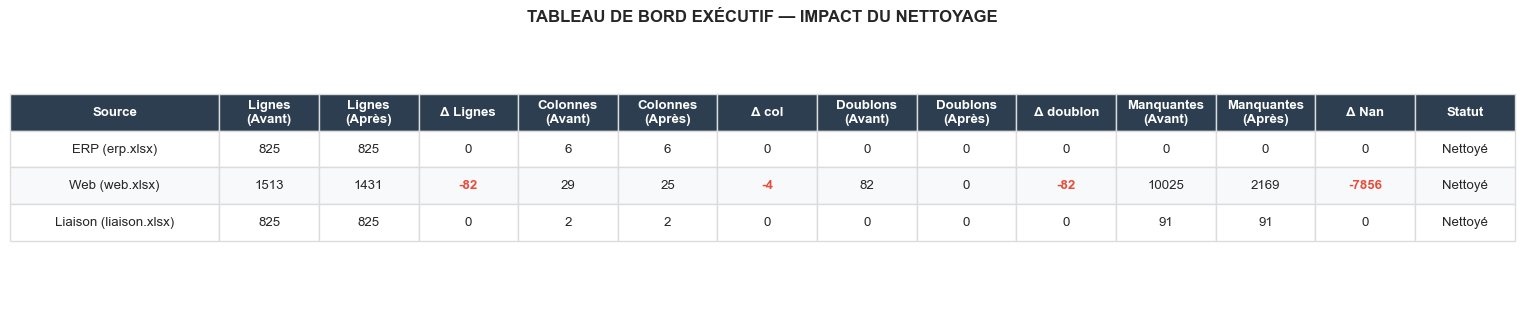

In [8]:
#===================================================
# COMPARAISON DE DONNEES AVANT ET APRES LE NETTOYAGE
#===================================================

# 2. Dictionnaire des sources nettoyées (après)
fichiers_apres = {
    'ERP (erp.xlsx)': df_erp,
    'Web (web.xlsx)': df_web,
    'Liaison (liaison.xlsx)': df_liaison
}

# 3. Génération et affichage du tableau comparatif
tableau_comparatif = generer_tableau_comparatif(fichiers_avant, fichiers_apres)

# Export en fichier Excel
tableau_comparatif.to_excel('Graphiques/tableau_comparatif_nettoyage.xlsx', index=False)

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - ANALYSE EXPLORATRICE DES DONNEES</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">4.1 - Analyse exploratoire du dataframe df_erp</h3>
</div>

In [9]:
# Correction et vérification du statut du stock dans l'ERP
# Règle : stock > 0 -> 'instock', stock <= 0 -> 'outofstock'

# Exemple : Exécuter une requête SQL pour trouver les erreurs de statut stock dans df_erp
query = """
    SELECT product_id, price, stock_quantity, stock_status
    FROM df_erp
    WHERE (stock_quantity > 0 AND stock_status = 'outofstock')
       OR (stock_quantity <= 0 AND stock_status = 'instock')
"""

df_erreurs_sql = duckdb.query(query).to_df()
display(df_erreurs_sql)

# 2. Application de la correction vectorisée
df_erp['stock_status'] = np.where(
    df_erp['stock_quantity'] > 0, 
    'instock', 
    'outofstock'
)
print("✓ Statuts stock mis à jour avec succès.")

,product_id,price,stock_quantity,stock_status
0,4039,46.00,3,outofstock
1,4885,18.70,0,instock


✓ Statuts stock mis à jour avec succès.


In [10]:
#--------------------------------------
# Prix & quantités négatifs
#---------------------------------------

# Identifier les produits dont le prix est négatif
query_prix_negatif = """
    SELECT product_id, price, stock_quantity, stock_status
    FROM df_erp
    WHERE price < 0 
"""

# Identifier les produits dont la quantité en stock est négative
query_quantite_negative = """
    SELECT product_id, price, stock_quantity, stock_status
    FROM df_erp
    WHERE stock_quantity < 0
"""

# Edition du résultat 
print("\n=== LISTE DES QUANTITÉS EN STOCK NÉGATIVES ===")
df_stock_negatif = duckdb.query(query_quantite_negative).to_df()
display(df_stock_negatif)

print("\n=== LISTE DES PRIX NÉGATIFS ===")
df_prix_negatif = duckdb.query(query_prix_negatif).to_df()
display(df_prix_negatif)

# Assertion de sécurité
assert df_erp['purchase_price'].isna().sum() == 0, "Erreur : Valeurs manquantes détectées dans purchase_price !"



=== LISTE DES QUANTITÉS EN STOCK NÉGATIVES ===


,product_id,price,stock_quantity,stock_status
0,4973,10.00,-10,outofstock
1,5700,44.50,-1,outofstock



=== LISTE DES PRIX NÉGATIFS ===


,product_id,price,stock_quantity,stock_status
0,4233,-20.00,0,outofstock
1,5017,-8.00,0,outofstock
2,6594,-9.10,19,instock


In [11]:
#-----------------------------------------
# Identifier les incohérences ero/web
#-----------------------------------------

# Requête SQL pour identifier et classifier les incohérences ERP/Web en une seule passe
query_incoherences_sql = """
    SELECT 
        product_id, 
        price, 
        stock_quantity, 
        stock_status, 
        onsale_web,
        CASE 
            WHEN stock_quantity > 0 AND onsale_web = 0 THEN 'Stock dormant (non publié)'
            WHEN stock_quantity <= 0 AND onsale_web = 1 THEN 'Rupture de stock (publié)'
            ELSE 'OK'
        END AS erreur_type
    FROM df_erp
    WHERE (stock_quantity > 0 AND onsale_web = 0)
       OR (stock_quantity <= 0 AND onsale_web = 1)
"""

df_anomalies_web = duckdb.query(query_incoherences_sql).to_df()

print(f"\n=== DÉTAIL DES INCOHÉRENCES WEB ({len(df_anomalies_web)} anomalies) ===")
with pd.option_context('display.max_rows', 15, 'display.max_columns', None):
    display(df_anomalies_web[['product_id', 'price', 'stock_quantity', 'stock_status', 'onsale_web', 'erreur_type']].head(10))

    
#-------------------------------------
# Exporter le résultat avec duckdb
#--------------------------------------

# Export en CSV (rapide et léger)
#duckdb.sql("COPY df_anomalies_web TO 'Export_resultats/anomalies_web.csv' (HEADER, DELIMITER ';')")

# Export en Parquet (format moderne haute performance)
duckdb.sql("COPY df_anomalies_web TO 'Export_Excel/anomalies_web.parquet' (FORMAT PARQUET)")

#-----------------------------------
# Exporter le résultat avec Pandas
#-----------------------------------

# Export Excel (.xlsx) sans l'index Pandas
df_anomalies_web.to_excel('Export_Excel/anomalies_web.xlsx', index=False, sheet_name='Anomalies_Web')

# Export CSV compatible Excel français (séparateur point-virgule et encodage UTF-8 BOM)
#df_anomalies_web.to_csv('Export_resultats/anomalies_web.csv', index=False, sep=';', encoding='utf-8-sig')



=== DÉTAIL DES INCOHÉRENCES WEB (113 anomalies) ===


,product_id,price,stock_quantity,stock_status,onsale_web,erreur_type
0,3850,20.80,0,outofstock,1,Rupture de stock (publié)
1,4043,60.00,0,outofstock,1,Rupture de stock (publié)
2,4047,18.30,0,outofstock,1,Rupture de stock (publié)
3,4051,7.70,0,outofstock,1,Rupture de stock (publié)
4,4052,33.70,0,outofstock,1,Rupture de stock (publié)
5,4065,19.50,0,outofstock,1,Rupture de stock (publié)
6,4079,37.00,0,outofstock,1,Rupture de stock (publié)
7,4100,15.80,0,outofstock,1,Rupture de stock (publié)
8,4138,25.70,0,outofstock,1,Rupture de stock (publié)
9,4179,24.00,0,outofstock,1,Rupture de stock (publié)


In [12]:
# Eliminer les erreurs de prix et les stocks négatifs
df_erp_clean = df_erp[(df_erp['price'] >= 0) & (df_erp['stock_quantity'] >= 0)].copy()

# Info erp après nettoyage
df_erp_clean.info()


<class 'pandas.DataFrame'>
Index: 820 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      820 non-null    int64  
 1   onsale_web      820 non-null    int64  
 2   price           820 non-null    float64
 3   stock_quantity  820 non-null    int64  
 4   stock_status    820 non-null    str    
 5   purchase_price  820 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 50.8 KB


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">4.2 - Analyse exploratoire du dataframe df_web</h3>
</div>

In [13]:
import duckdb

# 1. Requête DuckDB pour identifier les SKU manquants et les SKU avec caractères spéciaux
query_web_anomalies = """
    SELECT 
        sku, 
        post_title, 
        post_type, 
        total_sales, 
        post_date, 
        post_modified,
        CASE 
            WHEN sku IS NULL OR sku = '' OR sku = 'nan' THEN 'SKU manquant'
            WHEN regexp_matches(CAST(sku AS VARCHAR), '[-_]') THEN 'SKU avec caractère spécial'
            ELSE 'OK'
        END AS anomalie_type
    FROM df_web
    WHERE sku IS NULL OR sku = '' OR sku = 'nan' 
       OR regexp_matches(CAST(sku AS VARCHAR), '[-_]')
"""

df_web_anomalies = duckdb.query(query_web_anomalies).to_df()

# 2. Séparation pour l'affichage (similaire à ton code d'origine)
df_sans_sku = df_web_anomalies[df_web_anomalies['anomalie_type'] == 'SKU manquant']
df_speciaux = df_web_anomalies[df_web_anomalies['anomalie_type'] == 'SKU avec caractère spécial']

print(f"-> Nombre total de lignes avec un SKU manquant (NaN) : {len(df_sans_sku)}")
print("\n=== Tous les produits sans SKU ===")
display(df_sans_sku[['sku', 'post_title', 'post_type', 'total_sales', 'post_date', 'post_modified']].head())

print(f"\nNombre de SKU atypiques/spéciaux détectés : {len(df_speciaux)}")
print("Détail des SKU spéciaux :")
display(df_speciaux[['sku', 'post_title', 'total_sales', 'post_date', 'post_modified']].head())


-> Nombre total de lignes avec un SKU manquant (NaN) : 3

=== Tous les produits sans SKU ===


,sku,post_title,post_type,total_sales,post_date,post_modified
0,NaN,NaN,NaN,NaN,NaT,NaT
3,NaN,Pierre Jean Villa Condrieu Jardin Suspendu 2018,product,-56.00,2018-08-08 11:23:43,2019-11-02 13:24:01
4,NaN,Pierre Jean Villa Côte Rôtie Fongeant 2017,product,-17.00,2018-07-31 12:07:23,2019-11-02 13:24:15



Nombre de SKU atypiques/spéciaux détectés : 4
Détail des SKU spéciaux :


,sku,post_title,total_sales,post_date,post_modified
1,13127-1,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,4.00,2020-06-09 15:42:04,2020-07-20 17:09:06
2,bon-cadeau-25-euros,Bon cadeau de 25€,7.00,2018-06-01 13:53:46,2018-06-01 14:13:57
5,13127-1,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,4.00,2020-06-09 15:42:04,2020-07-20 17:09:06
6,bon-cadeau-25-euros,Bon cadeau de 25€,7.00,2018-06-01 13:53:46,2018-06-01 14:13:57


In [14]:
# 1. Attribution des SKU fictifs sur les lignes cibles
df_web.loc[1084, 'sku'] = 'sku_inconnu_1084'
df_web.loc[1087, 'sku'] = 'sku_inconnu_1087'

# 2. Filtrage des fiches produits, suppression des SKU nuls et nettoyage en une passe
df_web_clean = (
    df_web[
        (df_web['post_type'] == 'product') & 
        (df_web['sku'].notnull())
    ]
    .copy()
    .reset_index(drop=True)
)

# 3. Vérifications finales
print(f" - Nombre de lignes en double avant traitement: {df_web.duplicated(subset=['sku']).sum()}")
print(f" - Nombre de lignes en double après nettoyage : {df_web_clean.duplicated(subset=['sku']).sum()}")
print(f" - Nombre de lignes sans sku : {df_web_clean['sku'].isna().sum()}")
print(f" - Nombre de lignes en doublon : {df_web_clean.duplicated(subset=['sku']).sum()}")

 - Nombre de lignes en double avant traitement: 714
 - Nombre de lignes en double après nettoyage : 0
 - Nombre de lignes sans sku : 0
 - Nombre de lignes en doublon : 0


In [15]:
# 5. Suppression des colonnes superflues
colonnes_a_supprimer = [
    'post_author', 'post_excerpt', 'post_name', 'guid',
    'post_date_gmt', 'post_modified_gmt',
    'comment_status', 'ping_status', 'post_status', 
    'comment_count', 'menu_order', 'post_parent', 'post_mime_type'
]
cols_a_drop = [col for col in colonnes_a_supprimer if col in df_web_clean.columns]
df_web_clean = df_web_clean.drop(columns=cols_a_drop)

print(f"• Dimensions finales de df_web_clean : {df_web_clean.shape[0]} lignes, {df_web_clean.shape[1]} colonnes")
print("=" * 70)
print(df_web_clean.info())

• Dimensions finales de df_web_clean : 716 lignes, 12 colonnes
<class 'pandas.DataFrame'>
RangeIndex: 716 entries, 0 to 715
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   sku             716 non-null    object        
 1   virtual         716 non-null    int64         
 2   downloadable    716 non-null    int64         
 3   rating_count    716 non-null    int64         
 4   average_rating  716 non-null    float64       
 5   total_sales     716 non-null    float64       
 6   tax_status      716 non-null    str           
 7   post_date       716 non-null    datetime64[us]
 8   product_type    715 non-null    str           
 9   post_title      716 non-null    str           
 10  post_modified   716 non-null    datetime64[us]
 11  post_type       716 non-null    str           
dtypes: datetime64[us](2), float64(2), int64(3), object(1), str(4)
memory usage: 113.3+ KB
None


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">4.3 - Analyse exploratoire du dataframe df_liaison</h3>
</div>

In [16]:
# ==========================================================
# TRAITEMENT MÉTIER SPÉCIFIQUE : ANALYSE DE LA TABLE LIAISON
# ==========================================================

print("=" * 60)
print(" RAPPORT D'ANALYSE MÉTIER - TABLE DE LIAISON")
print("=" * 60)

# 1. Analyse de la colonne 'product_id' (Clé ERP)
nb_doublons_prod = df_liaison['product_id'].duplicated().sum()
nb_nan_prod = df_liaison['product_id'].isna().sum()
total_lignes = len(df_liaison)

print(f"• Colonne 'product_id' (ERP) :")
print(f"  - Doublons détectés : {nb_doublons_prod} / {total_lignes} (Unicité garantie : {nb_doublons_prod == 0})")
print(f"  - Valeurs manquantes : {nb_nan_prod}")

print("-" * 60)

# 2. Analyse de la colonne 'id_web' (Clé Web / SKU)
nb_doublons_web = df_liaison['id_web'].duplicated().sum()
nb_nan_web = df_liaison['id_web'].isna().sum()

print(f"• Colonne 'id_web' (Web) :")
print(f"  - Doublons détectés : {nb_doublons_web} / {total_lignes}")
print(f"  - Valeurs manquantes (NaN) : {nb_nan_web}")

print("-" * 60)

# 3. Isolation et qualification métier des produits non publiés en ligne
lignes_id_web_vides = df_liaison[df_liaison['id_web'].isna()].copy()
nb_produits_erp_hors_web = lignes_id_web_vides['product_id'].nunique()

print(f"• Analyse des ruptures de liaison :")
print(f"  - Nombre de produits présents dans l'ERP mais absents du Web : {nb_produits_erp_hors_web}")
print("  -> Interprétation : Ce sont des références physiques gérées en stock mais non référencées sur le site e-commerce.")
print("=" * 60)

# Afficher les principales colonnes de ces produits
display(lignes_id_web_vides)

# Export Excel
lignes_id_web_vides.to_excel('Export_Excel/id_web_vides.xlsx', index=False, sheet_name='lignes_id_web_vides')


 RAPPORT D'ANALYSE MÉTIER - TABLE DE LIAISON
• Colonne 'product_id' (ERP) :
  - Doublons détectés : 0 / 825 (Unicité garantie : True)
  - Valeurs manquantes : 0
------------------------------------------------------------
• Colonne 'id_web' (Web) :
  - Doublons détectés : 90 / 825
  - Valeurs manquantes (NaN) : 91
------------------------------------------------------------
• Analyse des ruptures de liaison :
  - Nombre de produits présents dans l'ERP mais absents du Web : 91
  -> Interprétation : Ce sont des références physiques gérées en stock mais non référencées sur le site e-commerce.


,id_web,product_id
19,NaN,4055
49,NaN,4090
50,NaN,4092
119,NaN,4195
131,NaN,4209
...,...,...
817,NaN,7196
818,NaN,7200
819,NaN,7201
820,NaN,7203


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); "> 5.1 Structure des fichiers ERP, WEB et Liaison à consolider </h3>
</div>

In [17]:
print(f"===================Dataframe ERP========================")
print(df_erp_clean.info())

print(f"===================Dataframe WEB========================")
print(df_web_clean.info())

print(f"===================Dataframe LIAISON========================")
print(df_liaison.info())

===================Dataframe ERP========================
<class 'pandas.DataFrame'>
Index: 820 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      820 non-null    int64  
 1   onsale_web      820 non-null    int64  
 2   price           820 non-null    float64
 3   stock_quantity  820 non-null    int64  
 4   stock_status    820 non-null    str    
 5   purchase_price  820 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 50.8 KB
None
===================Dataframe WEB========================
<class 'pandas.DataFrame'>
RangeIndex: 716 entries, 0 to 715
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   sku             716 non-null    object        
 1   virtual         716 non-null    int64         
 2   downloadable    716 non-null    int64         
 3   rating_count   

In [18]:
# Fusion globale via DuckDB en LEFT JOIN (en partant de l'ERP pour conserver tous les produits)
query_fusion = """
    SELECT 
        e.product_id,
        e.price,
        e.stock_quantity,
        e.stock_status,
        e.purchase_price,
        e.onsale_web,
        l.id_web,
        w.* EXCLUDE (sku)
    FROM df_erp_clean e
    LEFT JOIN df_liaison l ON e.product_id = l.product_id
    LEFT JOIN df_web_clean w ON l.id_web = w.sku
"""

df_final = duckdb.query(query_fusion).to_df()

print(f"• Dimensions du DataFrame global : {df_final.shape[0]} lignes, {df_final.shape[1]} colonnes")
#display(df_final.head(2))

# Afficher les lignes de df_final où id_web est manquant (les 91 produits ERP sans équivalent web)
df_ecart_erp = df_final[df_final['id_web'].isna()]


print(f"• Nombre total de produits ERP non référencés sur le web : {len(df_ecart_erp)}")

# Afficher les principales colonnes de ces produits
display(df_ecart_erp[['product_id', 'id_web', 'price', 'stock_quantity', 'stock_status', 'purchase_price']])
print(f"• Valeur stock des produits non référencé Web : {(df_ecart_erp['stock_quantity']*df_ecart_erp['purchase_price']).sum():2f}")

# Export Excel
df_ecart_erp.to_excel('Export_Excel/ecart_erp_web.xlsx', index=False, sheet_name='ecart_erp_web')


• Dimensions du DataFrame global : 820 lignes, 18 colonnes
• Nombre total de produits ERP non référencés sur le web : 87


,product_id,id_web,price,stock_quantity,stock_status,purchase_price
717,4055,NaN,86.10,0,outofstock,37.88
718,4090,NaN,73.00,0,outofstock,33.79
719,4092,NaN,47.00,0,outofstock,25.25
720,4195,NaN,14.10,0,outofstock,7.36
721,4209,NaN,73.50,0,outofstock,33.01
...,...,...,...,...,...,...
801,7196,NaN,31.00,55,instock,31.20
802,7200,NaN,31.00,6,instock,15.54
803,7201,NaN,31.00,18,instock,16.02
804,7203,NaN,45.00,30,instock,23.48


• Valeur stock des produits non référencé Web : 20982.180000


<div style="border: 1.5px solid black; padding: 10px;">
    <h2  style="color:Blue;"> Analyse du merge final</h2>
<h3>La logique métier (ERP = Référentiel central) :</h3>
<ul>
    <li> l'ERP est la source de vérité pour les produits : chaque ligne de l'ERP représente un produit réel de votre stock physique.</li>
    <li> Avec <b>how='left'</b>  en partant de l'ERP (ou du merge ERP + Liaison), on conserve exactement les 820 produits de l'ERP </li>
    <li> Si un produit est présent dans l'ERP mais n'a pas encore de correspondance sur le site web, il garde ses informations ERP et aura des NaN pour les colonnes web</li>    
<li>Avec <b> how = 'outer' </b>, on récupère absolument toutes les lignes de tous les fichiers, y compris des références présentes dans le fichier web ou de liaison mais qui n'existent plus dans l'ERP, ce qui fausse le nombre total de produits (ex 825(v1) lignes au lieu de 820). </li>      
</ul>
</div>

In [19]:
#----------------------------------------------------------------------
# Schéma 1 : Validation de la correspondance (product_id et id_web)
#----------------------------------------------------------------------
import pandera as pa
from pandera import Column, Check


# Schéma 1 : Focus sur la liaison ERP / Web
schema_liaison = pa.DataFrameSchema({
    "product_id": Column(int, Check.greater_than(0), nullable=False),
    # id_web est nullable=True car les produits hors web ont des NaN
    "id_web": Column(str, nullable=True)
}, strict=False) # strict=False permet d'ignorer les autres colonnes pour ce schéma

try:
    validated_liaison = schema_liaison.validate(df_final, lazy=True)
    print(" Schéma Liaison : Validation réussie.")
except pa.errors.SchemaErrors as err:
    print(" Échecs détectés sur le schéma Liaison (dont les NaN) :")
    display(err.failure_cases)


# LISTE DES PRODUITS ERP NON PUBLIES ( sans web_id
#-----------------------------------------------------

# Afficher la liste exacte des NaN (produits ERP non liés au web)
df_nan_web = df_final[df_final['id_web'].isna()]
display(df_nan_web[['product_id', 'id_web']])


 Schéma Liaison : Validation réussie.


C:\Users\compt\AppData\Local\Temp\ipykernel_12608\3771330317.py:9: FutureWarning: Importing pandas-specific classes and functions from the
top-level pandera module will be **removed in a future version of pandera**.
If you're using pandera to validate pandas objects, we highly recommend updating
your import:

```
# old import
import pandera as pa

# new import
import pandera.pandas as pa
```

If you're using pandera to validate objects from other compatible libraries
like pyspark or polars, see the supported libraries section of the documentation
for more information on how to import pandera:

https://pandera.readthedocs.io/en/stable/supported_libraries.html

To disable this warning, set the environment variable:

```
export DISABLE_PANDERA_IMPORT_WARNING=True
```

  schema_liaison = pa.DataFrameSchema({


,product_id,id_web
717,4055,NaN
718,4090,NaN
719,4092,NaN
720,4195,NaN
721,4209,NaN
...,...,...
801,7196,NaN
802,7200,NaN
803,7201,NaN
804,7203,NaN


In [20]:
#------------------------------------------------------------------------
# Schéma 2 : Validation pour les autres colonnes de df_final
#------------------------------------------------------------------------

# Schéma 2 : Validation des autres colonnes du DataFrame
schema_autres_colonnes = pa.DataFrameSchema({
    "price": Column(float, Check.ge(0), nullable=False),
    "stock_quantity": Column(int, Check.ge(0), nullable=False),
    "stock_status": Column(str, Check.isin(["instock", "outofstock"])),
    "purchase_price": Column(float, Check.ge(0), nullable=False),
    "onsale_web": Column(int, Check.isin([0, 1])),
    # Ajoutez ici d'autres colonnes de df_final à contrôler si nécessaire
}, strict=False) # strict=False pour ignorer product_id et id_web dans ce schéma

try:
    validated_autres = schema_autres_colonnes.validate(df_final, lazy=True)
    print(" Schéma Autres Colonnes : Validation réussie, toutes les règles métiers sont respectées.")
except pa.errors.SchemaErrors as err:
    print(" Échecs de validation détectés sur les autres colonnes :")
    display(err.failure_cases)
    

 Schéma Autres Colonnes : Validation réussie, toutes les règles métiers sont respectées.


<div style="border: 1.5px solid black; padding: 10px;">
<h4  style="color:Blue;"> Controle de la structure du dataframe final</h4> 
<p> Le jeu de données respecte rigoureusement le contrat de types et de contraintes métier défini. </p>
<ul>
<li> <b> Intégrité structurelle :</b> Les types (int, float, str) sont parfaitement alignés sur les colonnes clés</li>
<li> <b>Règles métier : </b> Aucun prix ou stock négatif ne subsiste, et les statuts de stock sont strictement limités aux valeurs attendues (instock ou outofstock)</li>
<li> <b> Fiabilité : </b> Zéro valeur nulle inattendue sur les champs critiques.</li>
</ul>    
</div>


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 6 - Analyse univariée du dataframe final</h2>
</div>

<div style="border: 1.5px solid black; padding: 10px;">
<h4  style="color:Blue;"> Nouvelle Stagtégie d'analyse</h4> 
 <p> Je réalise l'anayse sur deux dataframe. Un dataframe du cataloque global pour valoriser les sotcks et un dataframe du catalogue actif (total_Sales >0) pour l'analyse commerciale du mois d'octobre.</p>
<ul> 
<li> <b> Neutralisation des « articles dormants » (zéro vente) : </b> Le catalogue global contient souvent une part importante de produits qui n'ont jamais trouvé preneur. Les inclure dans un calcul global biaise mécaniquement la réalité opérationnelle (par exemple, en tirant artificiellement la moyenne des ventes ou la structure de Pareto vers le bas).
</li>
    
<li> <b> Précision de la loi de Pareto : </b> Distinguer les deux permet de voir si la concentration du chiffre d'affaires ou des volumes est portée par l'ensemble du catalogue ou si elle est encore plus prononcée sur le sous-ensemble des produits réellement actifs. Cela évite d'interpréter de fausses inefficiences dues à des références fantômes ou obsolètes.</li>

<li> <b> Aide à la décision (gestion des stocks / catalogue) : </b> Savoir que 80 % des ventes proviennent d'un certain pourcentage de produits actifs (et non de tout le catalogue confondu) donne une vision claire pour rationaliser l'offre : identifier ce qui tourne vraiment versus ce qui ennuie les stocks pour rien.</li>


</ul
</div>












<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 6.1 - Exploration du prix par la visualisation de données </h3>
</div>

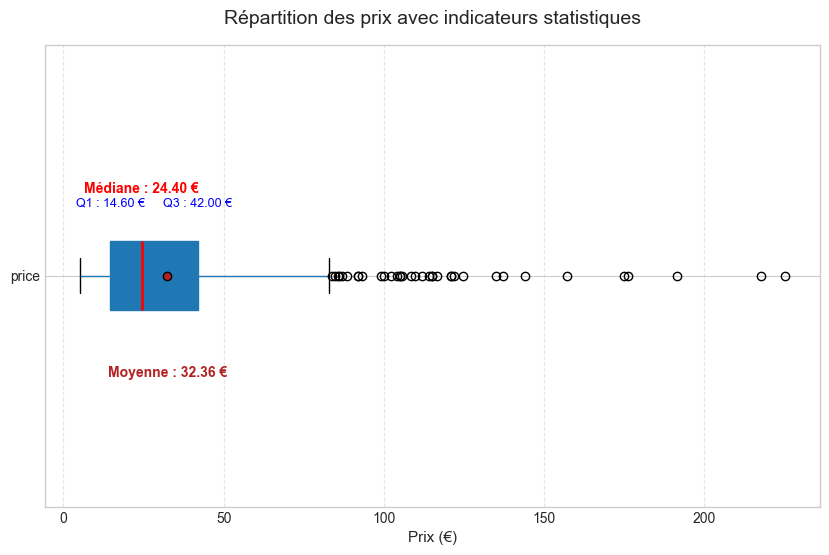

In [21]:
#------------------------------------------------------
# Distribution du prix (boite à moustache (boxplot)
#-----------------------------------------------------

# 1. S'assurer que le dossier d'export existe
os.makedirs("Graphiques", exist_ok=True)

# 2. Calcul des indicateurs statistiques
median = df_final['price'].median()
mean = df_final['price'].mean()
q1 = df_final['price'].quantile(0.25)
q3 = df_final['price'].quantile(0.75)

# 3. Création de la figure
plt.figure(figsize=(10, 6))

medianprops = {'color': 'red', 'linewidth': 2}
meanprops = {'marker': 'o', 'markeredgecolor': 'black', 'markerfacecolor': 'firebrick'}

df_final.boxplot(
    column='price',
    vert=False,
    patch_artist=True,
    showmeans=True,
    medianprops=medianprops,
    meanprops=meanprops
)

# 4. Ajout des étiquettes de données avec positionnement propre
plt.text(median, 1.18, f'Médiane : {median:.2f} €', color='red', fontweight='bold', ha='center', fontsize=10)
plt.text(mean, 0.78, f'Moyenne : {mean:.2f} €', color='firebrick', fontweight='bold', ha='center', fontsize=10)
plt.text(q1, 1.15, f'Q1 : {q1:.2f} €', ha='center', color='blue', fontsize=9)
plt.text(q3, 1.15, f'Q3 : {q3:.2f} €', ha='center', color='blue', fontsize=9)

# 5. Titres et style
plt.title('Répartition des prix avec indicateurs statistiques', fontsize=14, pad=15)
plt.xlabel('Prix (€)', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Export graphique haute résolution
plt.savefig("Graphiques/boxplot_analyse_prix.png", dpi=300, bbox_inches="tight")

# Affichage
plt.show()

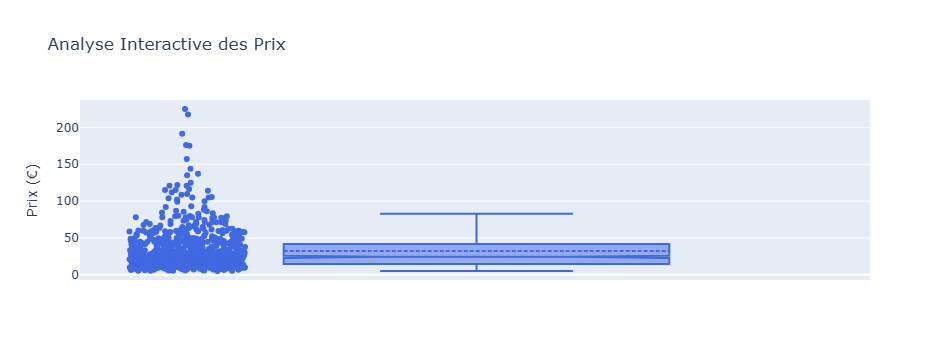

In [22]:
# Création du boxplot interactif

fig = px.box(df_final, 
             y="price", 
             points="all",        # Affiche tous les points à côté de la boîte
             notched=True,        # Ajoute une encoche à la médiane
             title="Analyse Interactive des Prix",
             labels={'price': 'Prix (€)'},
             hover_data=['post_title']) # Affiche le nom du vin au survol

# Personnalisation du design
fig.update_traces(marker_color='royalblue', boxmean=True) # Affiche aussi la moyenne

#Export au format html pour garder le style interactif
fig.write_html("Graphiques/analyse_interactif_prix.html")

#Affichage
fig.show()

<div style="border: 1.5px solid black; padding: 10px;">
<h4  style="color:Blue;"> Interprétation métier de la dictribution du prix :</h4> 
<ul>
    <li> <b> Asymétrie et valeurs extrêmes (Outliers) : </b> La présence d'une longue traîne de points isolés à droite (allant au-delà de 200 €) met en évidence de nombreux valeurs aberrantes ou prix d'exception. Ce sont ces prix élevés qui tirent la moyenne vers le haut (32,36 €) par rapport à la médiane (24,40 €).</li>
    <li> <b> Politique tarifaire : </b> Le gros du catalogue reste accessible (50 % des références entre 14,60 € et 42,00 €), tandis qu'une niche de produits haut de gamme se détache nettement sur l'axe des prix.</li>
</ul>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 6.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

In [23]:
# ========================================================================================================
# IDENTIFICATION DES OUTLIERS EN PRIX : Méthodes Z-SCORE (Z_indexe)  &  l'intervalle interquartile (IQR)
# ========================================================================================================
from sklearn.ensemble import IsolationForest

#----------------------------------
# --- 1. Méthode Z-Score ---
#------------------------------------

moyenne_prix = df_final['price'].mean()
ecart_t_prix = df_final['price'].std()

z_score_prix = (df_final['price'] - moyenne_prix) / ecart_t_prix
seuil_z3 = moyenne_prix + (3 * ecart_t_prix)

outliers_zscore = df_final[df_final['price'] > seuil_z3].copy()
outliers_zscore['z_score'] = round((outliers_zscore['price'] - moyenne_prix) / ecart_t_prix, 2)

print(f"IDENTIFICATION DES OUTLIERS EN PRIX : Méthode Z-SCORE :")
print(f"• Seuil de prix pour Z-score > 3 : {seuil_z3:.2f}€")
print(f"• Nombre d'outliers (Z-score) : {len(outliers_zscore)} produits sur {len(df_final)}")
print(f"• Proportion dans le catalogue : {(len(outliers_zscore) / len(df_final))*100: .2f}%\n" )


#--------------------------------------------------------
# --- 2. Méthode IQR (Intervalle Interquartile) ---
#-------------------------------------------------------

q1 = df_final['price'].quantile(0.25)
q3 = df_final['price'].quantile(0.75)
iqr = q3 - q1
seuil_max_iqr = q3 + 1.5 * iqr

# calcul des seuils
seuil_min = q1 - 1.5 * iqr
seuil_max = q3 + 1.5 * iqr

outliers_iqr = df_final[df_final['price'] > seuil_max_iqr].copy()

print()
print(f"IDENTIFICATION DES OUTLIERS EN PRIX : Méthode IQR :")
print(f"• Le seuil minimum du prix = {seuil_min: .2f}€")
print(f"• Le seuil maximum du prix = {seuil_max: .2f}€")
print(f"• Nombre d'outliers (IQR) : {len(outliers_iqr)} produits sur {len(df_final)}")
print(f"• Proportion dans le catalogue : {(len(outliers_iqr) / len(df_final)) * 100:.2f}%")


#-----------------------------------------
# --- 2. Méthode Isolation Forest ---
#-----------------------------------------

# 1. Préparation des données (Isolation Forest a besoin d'un tableau 2D)
X = df_final[['price']].dropna()

# 2. Initialisation et entraînement du modèle
iso = IsolationForest(contamination=0.03, random_state=42)
df_final['outlier_if'] = iso.fit_predict(X)

# Isolation Forest retourne 1 pour les points normaux et -1 pour les outliers
df_final['is_outlier'] = df_final['outlier_if'] == -1

# 3. Filtrage des outliers
outliers_if = df_final[df_final['is_outlier']].copy()

# 4. Affichage formaté similaire aux autres méthodes
print()
print(f"IDENTIFICATION DES OUTLIERS EN PRIX : Méthode ISOLATION FOREST :")
print(f"• Nombre d'outliers (Isolation Forest) : {len(outliers_if)} produits sur {len(df_final)}")
print(f"• Proportion dans le catalogue : {(len(outliers_if) / len(df_final)) * 100:.2f}%\n")


# Affichage du Top des produits de prestige (triés par prix décroissant)
#print("\n Aperçu des 10 principaux produits outliers par prix :")
#display(outliers_zscore [['product_id', 'post_title', 'price', 'purchase_price']].sort_values(by='price', ascending=False).head(10))
#display(outliers_iqr[['product_id', 'post_title', 'price', 'purchase_price']].sort_values(by='price', ascending=False).head(10))
#display(outliers_if[['product_id', 'post_title', 'price', 'purchase_price']].sort_values(by='price', ascending=False).head(10))


IDENTIFICATION DES OUTLIERS EN PRIX : Méthode Z-SCORE :
• Seuil de prix pour Z-score > 3 : 112.28€
• Nombre d'outliers (Z-score) : 17 produits sur 820
• Proportion dans le catalogue :  2.07%


IDENTIFICATION DES OUTLIERS EN PRIX : Méthode IQR :
• Le seuil minimum du prix = -26.50€
• Le seuil maximum du prix =  83.10€
• Nombre d'outliers (IQR) : 36 produits sur 820
• Proportion dans le catalogue : 4.39%

IDENTIFICATION DES OUTLIERS EN PRIX : Méthode ISOLATION FOREST :
• Nombre d'outliers (Isolation Forest) : 25 produits sur 820
• Proportion dans le catalogue : 3.05%



<div style="border: 1.5px solid black; padding: 10px;">
<h2  style="color:Blue;"> Méthodes statistiques pour détecter les ouliers :</h2> 
<ul>
<h4> <b> 1. Méthode Z-Score :</b> </h4>
<ul>
    <li> <b> Description : </b>Elle mesure l'écart entre chaque prix et la moyenne du catalogue en unités d'écart-type. Un seuil strict (généralement supérieur à 3) isole les valeurs les plus extrêmes.</li>
    <li> <b> Importance : </b> Elle permet d'identifier de manière très rigoureuse les "méga-valeurs" ou prix aberrants absolus (ici, 17 produits au-delà de 112,28 €) qui s'écartent drastiquement de la norme.</li>
</ul>

<h4> <b> 2. Méthode IQR (Écart Interquartile) :</b> </h4>
<ul>    
    <li> <b> Description : </b> Basée sur la dispersion des données autour de la médiane (entre le premier et le troisième quartile), elle définit des bornes au-delà desquelles un prix est considéré comme atypique./li>
   <li> <b> Importance : </b> Plus sensible que le Z-Score, elle repère un plus grand nombre de valeurs atypiques (36 produits au-dessus de 83,10 €) en s'affranchissant de l'influence excessive des prix extrêmes.</li>
</ul>

 <h4> <b> 3. Méthode Isolation Forest :</b> </h4>
<ul>   
    <li> <b>Description : </b> Un algorithme de machine learning non supervisé qui isole les observations en construisant des arbres de décision aléatoires, les valeurs rares étant plus rapides à isoler.</li>
   <li> <b> Importance :</b> Elle offre une approche intelligente et multidimensionnelle (25 produits détectés) pour capturer des profils de prix atypiques complexes qui échappent parfois aux règles statistiques linéaires simples.   </li>
</ul>

<h4> <b>Utilité globale pour l'analyse :</b> </h4>
<p>L'utilisation conjointe de ces trois approches (via un système de consensus) garantit une objectivité parfaite : elle permet de distinguer les véritables produits de luxe et grands crus (qui font l'identité de la boutique) des éventuelles erreurs de saisie, sans fausser les indicateurs de tendance centrale (moyenne et médiane).</p>

</ul>

<div style="border: 1.5px solid black; padding: 10px;">
<h2  style="color:Blue;"> Principe du consensus et de drapeaux</h2> 

    
<p> Un système de consensus et de drapeaux (ou flags en programmation) est une méthode qui consiste à croiser plusieurs sources ou algorithmes de détection pour prendre une décision fiable.</p>

<p> Voici comment cela fonctionne concrètement dans ton projet : </p>

<ul>
    <li> <b> Les drapeaux (Flags) : </b> Ce sont de simples colonnes booléennes (Vrai ou Faux) ajoutées à ton DataFrame pour chaque produit. Par exemple, outlier_zscore vaut True si le produit est détecté comme anormal par le Z-Score, et False sinon.
</li>
    <li> <b>Le consensus :  </b> Au lieu de faire confiance aveuglément à une seule méthode (qui pourrait se tromper ou être trop stricte), tu regardes l'accord entre les trois méthodes. Un produit ne sera considéré comme un réel outlier ou cas particulier que si plusieurs méthodes (par exemple, à la fois l'IQR et l'Isolation Forest) s'accordent à dire qu'il est atypique.</li>
</ul>
<p> Cela permet d'éliminer les faux positifs et d'avoir une vision statistique beaucoup plus robuste. </p>
</div>

In [24]:
# --- 3. Intégration et score de consensus ---
# Création des drapeaux booléens à partir de tes seuils existants
df_final['outlier_zscore'] = df_final['price'] > seuil_z3
df_final['outlier_iqr'] = df_final['price'] > seuil_max_iqr
# (S'assure que 'is_outlier' existe bien suite à l'étape Isolation Forest)
if 'is_outlier' not in df_final.columns:
    df_final['is_outlier'] = False

# Calcul de la somme des votes (0 à 3)
df_final['consensus_count'] = (
    df_final['outlier_zscore'].astype(int) +
    df_final['outlier_iqr'].astype(int) +
    df_final['is_outlier'].astype(int)
)

# Filtrage des produits validés par au moins 2 méthodes
outliers_forts = df_final[df_final['consensus_count'] >= 2][
    ['product_id', 'post_title', 'price', 'consensus_count', 'purchase_price']
]

print(f"\n--- SYNTHÈSE DU CONSENSUS ---")
print(f"Nombre de produits identifiés comme outliers par au moins 2 méthodes : {len(outliers_forts)}")
#display(outliers_forts.sort_values(by='price', ascending=False))



--- SYNTHÈSE DU CONSENSUS ---
Nombre de produits identifiés comme outliers par au moins 2 méthodes : 25


In [25]:
# ========================================================================================================
# ANALYSE DES OUTLIERS FORTS EN PRIX : Calcul du coefficient commercial et qualification de la marge
# ========================================================================================================


# 1. Enregistrement de la table des outliers forts dans DuckDB 
duckdb.register('df_duck', outliers_forts)

# 2. Vue macro de synthèse affichée en console
query_synthese = """
    SELECT 
        CASE 
            WHEN purchase_price IS NULL OR purchase_price = 0 THEN '❓ Coût d''achat manquant'
            WHEN (price / purchase_price) < 1 THEN '⚠️ Vente à perte'
            WHEN (price / purchase_price) < 1.5 THEN '🔶 Marge faible'
            WHEN (price / purchase_price) < 3 THEN '✅ Marge normale'
            WHEN (price / purchase_price) < 5 THEN '⭐ Marge élevée'
            ELSE '💎 Prix potentiellement abusif / Luxe'
        END AS "Catégorie de marge",
        COUNT(*) AS "Nombre de produits"
    FROM df_duck
    GROUP BY 1
    ORDER BY "Nombre de produits" DESC
"""

print("📊 SYNTHÈSE DE LA RENTABILITÉ DES OUTLIERS :")
display(duckdb.sql(query_synthese).df())

# 3. Calcul du détail en arrière-plan (sans affichage console) et export via Pandas
query_detail = """
    SELECT 
        product_id,
        post_title,
        price,
        purchase_price,
        ROUND(price / NULLIF(purchase_price, 0), 2) AS coef_commercial,
        CASE 
            WHEN purchase_price IS NULL OR purchase_price = 0 THEN '❓ Coût d''achat manquant'
            WHEN (price / purchase_price) < 1 THEN '⚠️ Vente à perte'
            WHEN (price / purchase_price) < 1.5 THEN '🔶 Marge faible'
            WHEN (price / purchase_price) < 3 THEN '✅ Marge normale'
            WHEN (price / purchase_price) < 5 THEN '⭐ Marge élevée'
            ELSE '💎 Prix potentiellement abusif / Luxe'
        END AS commentaire
    FROM df_duck
    ORDER BY coef_commercial DESC NULLS LAST
"""

df_detail_rentabilite = duckdb.sql(query_detail).df()
#print(f"✅ Détail de la rentabilité ({len(df_detail_rentabilite)} produits) \n {df_detail_rentabilite}")

# Création du dossier d'export si nécessaire et sauvegarde en CSV / Excel
os.makedirs("Export_Excel", exist_ok=True)
chemin_export = "Export_Excel/detail_rentabilite_outliers.xlsx"
df_detail_rentabilite.to_excel(chemin_export, index=False)

print(f"✅ Détail de la rentabilité ({len(df_detail_rentabilite)} produits) exporté avec succès dans : {chemin_export}")


📊 SYNTHÈSE DE LA RENTABILITÉ DES OUTLIERS :


,Catégorie de marge,Nombre de produits
0,✅ Marge normale,25


✅ Détail de la rentabilité (25 produits) exporté avec succès dans : Export_Excel/detail_rentabilite_outliers.xlsx


<div style="border: 1.5px solid black; padding: 10px;">
<h2  style="color:Blue;"> Analyse du consensus appliqué</h2> 
    
<p> En exigeant qu'un produit soit validé par au moins 2 méthodes sur 3, on met en place un filtre de consensus qui présente deux avantages majeurs :</p>

<ul>
    <li> <b> Élimination des faux positifs : </b> Chaque méthode statistique a ses limites (le Z-Score est très sensible à la moyenne, l'IQR repose uniquement sur les quartiles, et l'Isolation Forest peut parfois sur-détecter). Le croisement permet d'isoler les cas vraiment atypiques.</li>
    <li> <b> Sécurité pour les décisions métier :  </b> Obtenir exactement 25 produits consensuels (exportés dans un fichier Excel) nous donne une liste propre et incontestable de produits de luxe ou d'exception à analyser ou à surveiller de près, sans risquer de corrompre les indicateurs globaux avec des erreurs de calcul ou de saisie isolées. </li>
</ul>
<p> On dispose desormais d'une liste d'anomalies parfaitement qualifiée (25 produits). </p>
<p> NB : Le fait que l'Isolation Forest et le consensus affichent tous les deux exactement 25 produits est un hasard mathématique.</p>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 6.3 - Analyse du chiffre d'affaires (Montant & quantité)</h3>
</div>

In [26]:
#-------------------------------------------------------------------------------------------------------------------------------------------
# CA DU MOIS D'OCTOBRE  
# NB: Extraction au 31/10 ; total_sales = ventes du 01/10 au 31/10 (énoncé de la mission). Rotation (mois) = stock / ventes du mois. »
#--------------------------------------------------------------------------------------------------------------------------------------------

# 1. Enregistrement de ton DataFrame dans DuckDB
duckdb.register('df_duck_ca', df_final)

# 2. Requête SQL pour enrichir le DataFrame avec la colonne CA
df_final = duckdb.sql("""
    SELECT 
        *, 
        COALESCE(total_sales, 0) * COALESCE(price, 0) AS CA
    FROM df_duck_ca
""").df()

# 3. Calcul de la somme totale directement depuis le DataFrame mis à jour
total_CA = df_final['CA'].sum()

# 4. Affichage du résultat
print(f"💰 Chiffre d'affaires total du catalogue (DuckDB) : {total_CA:,.2f} €".replace(',', ' '))


💰 Chiffre d'affaires total du catalogue (DuckDB) : 143 324.10 €


<div style="border: 1.5px solid black; padding: 10px;">
<h4  style="color:Blue;">Analyse prix : justification ecart avec le CA (normal) </h4>
<ul>
    <li>CA 'normal' : 143680.1 €</li>
    <li>Mon CA :  143324.10 €</li>
    <li>Soit un écart de 356 €</li>
</ul>
   
<p>Explication:</p>
<p> - Il s'agit de du product_id '5700' du fichier ERP dont la quantité en stock = -1, un statut 'outofstock', et SKU = 14736. De mon coté, je l'ai supprimé en phase nettoyage car on ne peut pas vendre un produit qui est en rupture de stock</p>
<p> - Intérgrer ce produit dans le merge total parce qu'il y'a 8 bouteilles vendues au prix de 44,5€ génère un CA de 356€ expliquant exactement mon écart mais techniquement irréaliste </p>
<p>Décision : Par mesure de prudence et pour garantir la fiabilité l'analyse, j'ai choisi d'exclure cette ligne. Un Chiffre d'Affaires qui ne peut être honoré par une livraison physique est considéré comme une erreur de flux ou une transaction en attente d'annulation.</p>

- [DuckDB] Catalogue Global -> Nombre d'articles représentant 80% du CA : 433 / 820
- [DuckDB] Catalogue Global -> Proportion par rapport au catalogue : 52.80% 

- [DuckDB] Produits Actifs (total_sales > 0) -> Nombre d'articles représentant 80% du CA : 433 / 688
- [DuckDB] Produits Actifs (total_sales > 0) -> Proportion par rapport au catalogue : 62.94% 



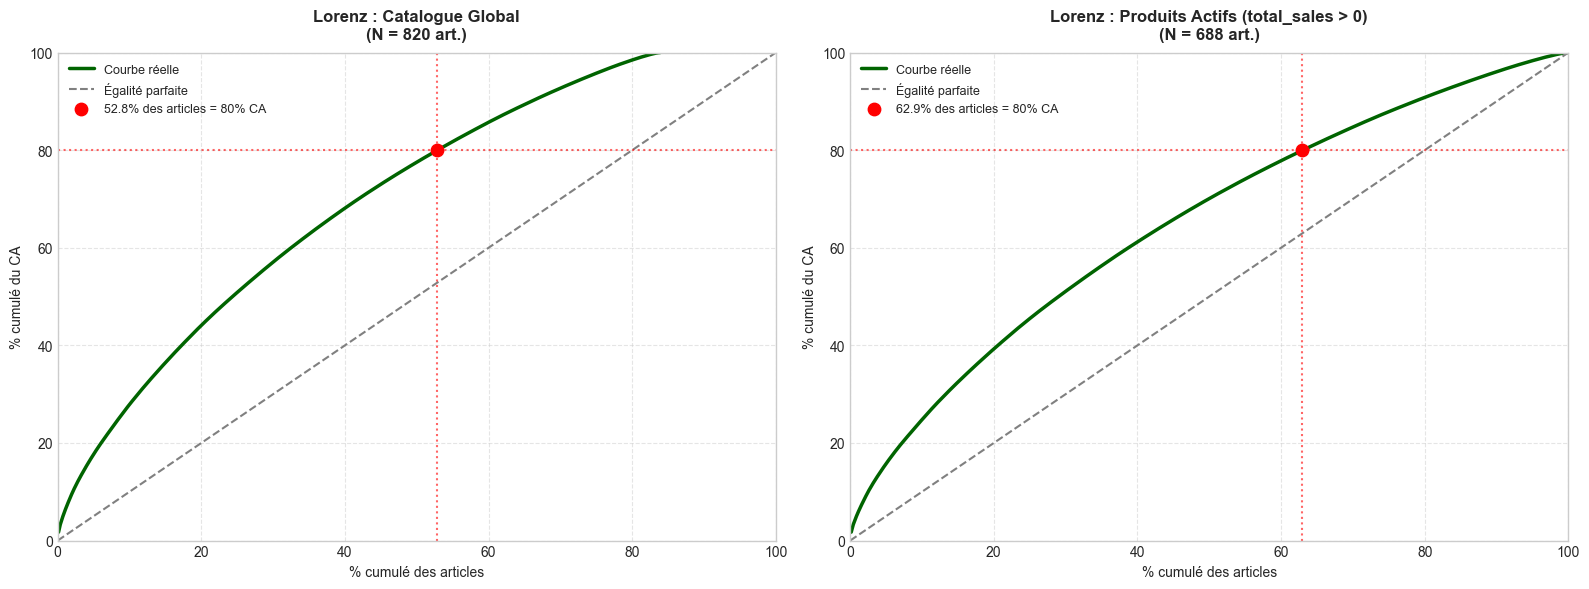

In [27]:
# ========================================================================================================
#  ANALYSE CA EN VALEUR
# ========================================================================================================

# COURBE DE LORENZ & PARETO du CA (Comparatif df_Global vs df_Produits_Actifs)

# 1. Enregistrement du DataFrame global dans DuckDB
duckdb.register('df_global', df_final)

# 2. Définition des requêtes SQL pour extraire et préparer les deux datasets proprement
# Requête pour le catalogue global
query_global = """
    WITH ranked AS (
        SELECT 
            COALESCE(price, 0) * COALESCE(total_sales, 0) AS CA
        FROM df_global
        WHERE COALESCE(price, 0) * COALESCE(total_sales, 0) > 0
        ORDER BY CA DESC
    ),
    cumul AS (
        SELECT 
            CA,
            SUM(CA) OVER (ORDER BY CA DESC ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS ca_cumul,
            SUM(CA) OVER () as ca_total,
            ROW_NUMBER() OVER (ORDER BY CA DESC) as rang,
            COUNT(*) OVER () as n_total
        FROM ranked
    )
    SELECT 
        rang,
        (ca_cumul * 100.0 / ca_total) AS cumul_part_ca
    FROM cumul
"""

# Requête pour les produits actifs uniquement (total_sales > 0 et CA > 0)
query_actifs = """
    WITH ranked AS (
        SELECT 
            COALESCE(price, 0) * COALESCE(total_sales, 0) AS CA
        FROM df_global
        WHERE COALESCE(total_sales, 0) > 0 AND COALESCE(price, 0) * COALESCE(total_sales, 0) > 0
        ORDER BY CA DESC
    ),
    cumul AS (
        SELECT 
            CA,
            SUM(CA) OVER (ORDER BY CA DESC ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS ca_cumul,
            SUM(CA) OVER () as ca_total,
            ROW_NUMBER() OVER (ORDER BY CA DESC) as rang,
            COUNT(*) OVER () as n_total
        FROM ranked
    )
    SELECT 
        rang,
        (ca_cumul * 100.0 / ca_total) AS cumul_part_ca
    FROM cumul
"""

# Exécution des requêtes vers des DataFrames Pandas pour le tracé
df_res_global = duckdb.sql(query_global).df()
# Pour le N total du catalogue global (incluant les ventes à 0 si besoin de les compter dans le total du catalogue)
n_catalog_total = len(df_final)
n_actifs_total = len(df_final[df_final['total_sales'] > 0])

df_res_actifs = duckdb.sql(query_actifs).df()

datasets = {
    "Catalogue Global": (df_res_global, n_catalog_total),
    "Produits Actifs (total_sales > 0)": (df_res_actifs, n_actifs_total)
}

# 3. Création des sous-graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (nom, (df_subset, n_total)) in zip(axes, datasets.items()):
    n_articles = len(df_subset)
    
    # Recherche du nombre d'articles représentant 80% du CA
    articles_80_rows = df_subset[df_subset['cumul_part_ca'] <= 80]
    nb_articles_80 = len(articles_80_rows)
    if nb_articles_80 == 0 and n_articles > 0:
        nb_articles_80 = 1 # Sécurité
        
    prop_articles_80 = (nb_articles_80 / n_total) * 100 if n_total > 0 else 0

    print(f"- [DuckDB] {nom} -> Nombre d'articles représentant 80% du CA : {nb_articles_80} / {n_total}")
    print(f"- [DuckDB] {nom} -> Proportion par rapport au catalogue : {prop_articles_80:.2f}% \n")

    # Coordonnées pour la courbe de Lorenz
    x_values = np.arange(1, n_articles + 1) / n_total * 100 if n_total > 0 else [0]
    y_values = df_subset['cumul_part_ca'].values

    # Traçage des courbes
    ax.plot(x_values, y_values, color='#006400', linewidth=2.5, label='Courbe réelle')
    ax.plot([0, 100], [0, 100], color='grey', linestyle='--', label='Égalité parfaite')

    # Point d'inflexion (80/20)
    ax.axvline(x=prop_articles_80, color='red', linestyle=':', alpha=0.6)
    ax.axhline(y=80, color='red', linestyle=':', alpha=0.6)
    ax.scatter(prop_articles_80, 80, color='red', s=80, zorder=5, 
               label=f'{prop_articles_80:.1f}% des articles = 80% CA')

    # Habillage de chaque subplot
    ax.set_title(f'Lorenz : {nom}\n(N = {n_total} art.)', fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel('% cumulé des articles', fontsize=10)
    ax.set_ylabel('% cumulé du CA', fontsize=10)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

# Export & Affichage
os.makedirs("Graphiques", exist_ok=True)
plt.savefig("Graphiques/CA_Pareto_Comparatif_DuckDB.png", dpi=300, bbox_inches="tight")
plt.show()

<div style="border: 1.5px solid black; padding: 10px;">
<h4  style="color:Blue;"> Concentration du chiffre d'affaires en valeur </h4>
<p> L'analyse est faite sur deux dataframe distincs ce qui nous donne ces deux graphiques de courbes de Lorenz</p>
<ul>
    <li> <b> Graphique de gauche (Catalogue Global - 820 art.) : </b> Il intègre l'ensemble du catalogue, y compris les 132 produits qui n'ont jamais été vendus (stock dormant). Cela décale légèrement la courbe vers la droite au départ.</li>
    <li> <b> Graphique de droite (Produits Actifs - 688 art.) : </b> Il se focalise uniquement sur les produits ayant généré au moins une vente (total_sales > 0).</li>
   
</ul>
<h5> <b>Interprétation métier : </b></h5>
<ul>
    <li> On observe une forte asymétrie (la courbe s'éloigne nettement de la diagonale de l'égalité parfaite), ce qui est classique en e-commerce et en distribution : une minorité de références porte la grande majorité du chiffre d'affaires.</li>
     <li> La comparaison entre les deux graphiques montre que le fait d'inclure les produits non vendus alourdit mécaniquement le catalogue mais ne modifie pas fondamentalement la structure de concentration des ventes sur les best-sellers.</li>
</ul>
</ul>

,Jeu de données,Effectif (N),Volume Total (unités),Nb produits pour 80%,Volume 80% cible
0,Catalogue Global,820,"5,743",432 (52.68 %),"4,592 unités"
1,Produits Actifs (total_sales > 0),688,"5,743",432 (62.79 %),"4,592 unités"


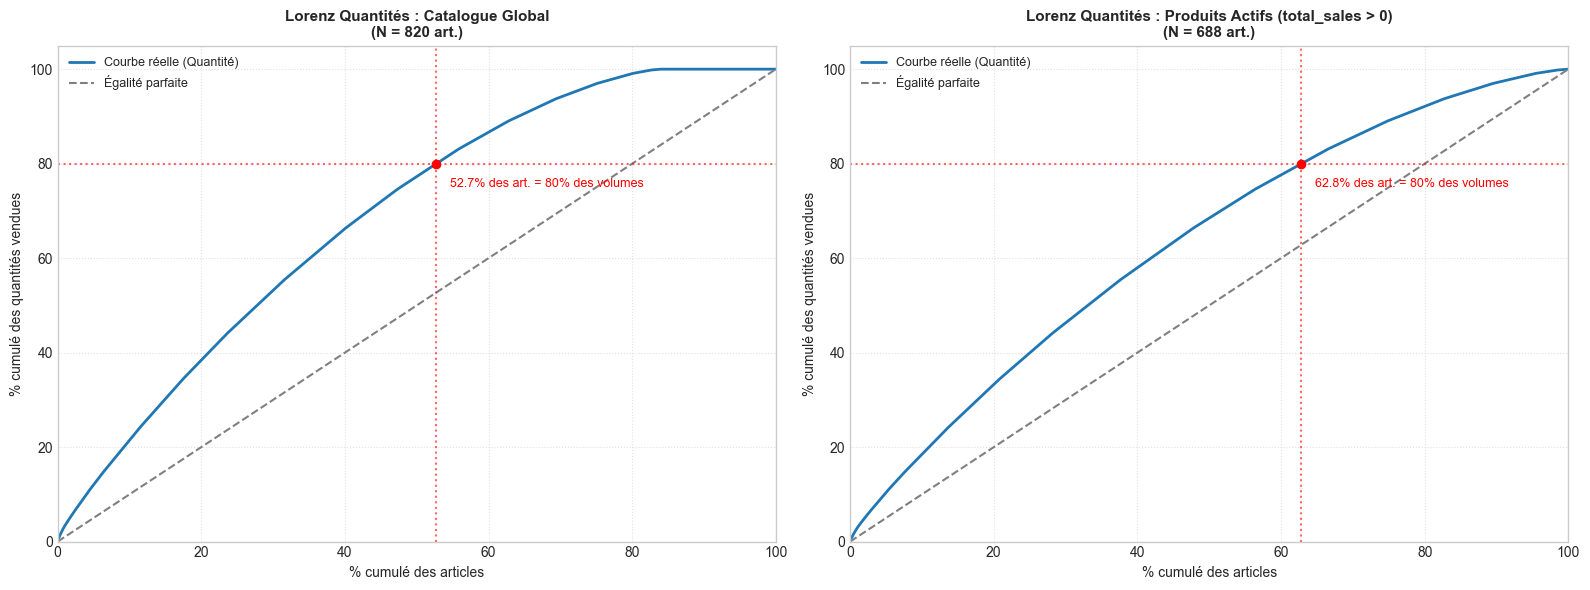

In [28]:
# ==============================================
#  ANALYSE  CA EN QUANTITÉ (Volumes)
# =============================================


# COURBES DE LORENZ / PARETO EN QUANTITÉ (Comparatif Global vs Produits Actifs)

# 1. Définition des sous-ensembles
datasets = {
    "Catalogue Global": df_final.copy(),
    "Produits Actifs (total_sales > 0)": df_final[df_final['total_sales'] > 0].copy()
}

synthese_qte = []
figures_data = {}

for nom, df in datasets.items():
    duckdb.register('df_sub', df)
    
    df_pareto = duckdb.query("""
        SELECT 
            post_title,
            COALESCE(total_sales, 0) AS total_sales,
            SUM(COALESCE(total_sales, 0)) OVER () as total_qte,
            COUNT(*) OVER () as n_articles
        FROM df_sub
        ORDER BY total_sales DESC
    """).df()
    
    total_qte = df_pareto['total_qte'].iloc[0] if len(df_pareto) > 0 else 0
    n_articles = df_pareto['n_articles'].iloc[0] if len(df_pareto) > 0 else 0
    
    if total_qte > 0 and n_articles > 0:
        df_pareto['Part-quantité (%)'] = (df_pareto['total_sales'] / total_qte) * 100
        df_pareto['Cumul-part-qte (%)'] = df_pareto['Part-quantité (%)'].cumsum()
        df_pareto['Part-produits (%)'] = (np.arange(1, n_articles + 1) / n_articles) * 100
        
        qte_80 = df_pareto[df_pareto['Cumul-part-qte (%)'] <= 80]
        nbr_produit_80 = len(qte_80)
        volume_ventes_80 = qte_80['total_sales'].sum()
        prop_catalogue = (nbr_produit_80 / n_articles) * 100
    else:
        nbr_produit_80 = 0
        volume_ventes_80 = 0
        prop_catalogue = 0
        
    synthese_qte.append({
        'Jeu de données': nom,
        'Effectif (N)': n_articles,
        'Volume Total (unités)': f"{total_qte:,.0f}",
        'Nb produits pour 80%': f"{nbr_produit_80} ({prop_catalogue:.2f} %)",
        'Volume 80% cible': f"{volume_ventes_80:,.0f} unités"
    })
    
    figures_data[nom] = (df_pareto, prop_catalogue, n_articles)

# 2. Tableau de synthèse
df_synthese_qte = pd.DataFrame(synthese_qte)
display(df_synthese_qte)

# 3. Génération des graphiques avec les repères Pareto (lignes rouges et points)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for i, (nom, (df_p, prop_cat, n_art)) in enumerate(figures_data.items()):
    ax = axes[i]
    if len(df_p) > 0:
        # Courbe cumulée
        ax.plot(df_p['Part-produits (%)'], df_p['Cumul-part-qte (%)'], color='#1f77b4', lw=2, label='Courbe réelle (Quantité)')
        ax.plot([0, 100], [0, 100], color='gray', linestyle='--', label='Égalité parfaite')
        
        # Repères 80% (point et lignes pointillées)
        ax.axhline(80, color='red', linestyle=':', alpha=0.6)
        ax.axvline(prop_cat, color='red', linestyle=':', alpha=0.6)
        ax.scatter([prop_cat], [80], color='red', zorder=5)
        
        ax.text(prop_cat + 2, 75, f"{prop_cat:.1f}% des art. = 80% des volumes", color='red', fontsize=9)
        
        ax.set_title(f"Lorenz Quantités : {nom}\n(N = {n_art} art.)", fontsize=11, fontweight='bold')
        ax.set_xlabel("% cumulé des articles")
        ax.set_ylabel("% cumulé des quantités vendues")
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 105)
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()

# Export & Affichage
os.makedirs("Graphiques", exist_ok=True)
plt.savefig("Graphiques/CA_Volume_Pareto_Comparatif.png", dpi=300, bbox_inches="tight")

# Afficher le graphique
plt.show()

<div style="border: 1.5px solid black; padding: 10px;">
<h4  style="color:Blue;"> Concentration du chiffre d'affaires en volume </h4>
<p> Le point rouge indique qu'environ 52,7 % des volumes du catalogue globale (820 produits) et 60,80 % des volumes des produits du mois d'octobre (total_sales > 0) représentent 80% du cumul des articles traduisant une concentration un peu moins violente en volume qu'en valeur.</p>

</div>

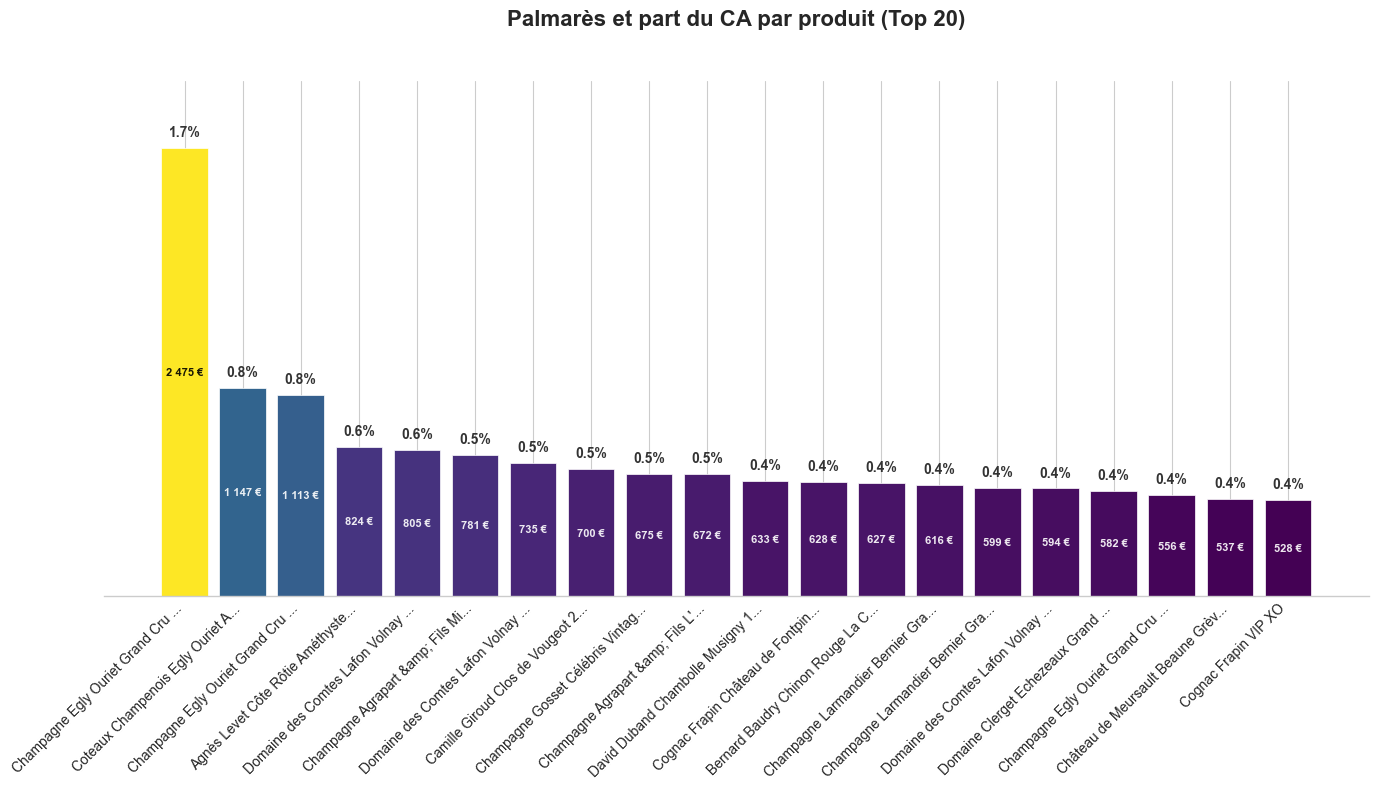

In [29]:
#==========================================================================================================
# PALMARÈS : Top 20 des articles générant le plus de Chiffre d'Affaires & leur proportion
# ======================================================================================================== 

import matplotlib.cm as cm
# 1. Enregistrement de ton DataFrame dans DuckDB
duckdb.register('df_duck_top', df_final)

# 1. Requête propre pour récupérer le Top 20 du plus grand au plus petit
top20 = duckdb.query("""
    SELECT product_id, post_title, price, total_sales, CA
    FROM df_duck_top
    ORDER BY CA DESC
    LIMIT 20
""").df()

# 2. Configuration de la figure
fig, ax = plt.subplots(figsize=(14, 8))

ca_values = top20['CA'].values
total_ca = df_final['CA'].sum() # On prend la somme du CA de TOUT le catalogue global
raw_names = top20['post_title'].astype(str).values

clean_names = [n.replace('-', ' ')[:32] + '...' if len(n) > 32 else n.replace('-', ' ') for n in raw_names]
x_pos = np.arange(len(clean_names))

# 3. Couleurs (Viridis)
norm = plt.Normalize(ca_values.min(), ca_values.max())
colors = cm.viridis(norm(ca_values))

# 4. Création des barres
bars = ax.bar(x_pos, ca_values, color=colors, edgecolor='white', linewidth=0.5)

# 5. Placement des informations (Pourcentages et Valeurs)
for i, bar in enumerate(bars):
    height = bar.get_height()
    perc = (height / total_ca) * 100
    
    # --- INFO 1 : POURCENTAGE EN TÊTE (EN DEHORS) ---
    y_top = height + (ca_values.max() * 0.02)
    ax.text(bar.get_x() + bar.get_width()/2, y_top, 
            f"{perc:.1f}%", 
            ha='center', va='bottom', 
            fontsize=10, fontweight='bold', color='#333333')
    
    # --- INFO 2 : CA AU MILIEU (AVEC SYMBOLE €) ---
    text_color_inner = 'black' if i == 0 else 'white'
    
    if height > (ca_values.max() * 0.1): 
        y_mid = height / 2
        ax.text(bar.get_x() + bar.get_width()/2, y_mid, 
                f"{int(height):,} €".replace(',', ' '), 
                ha='center', va='center', 
                fontsize=8, fontweight='bold', color=text_color_inner,
                alpha=0.9)

# 6. Esthétique des axes
ax.set_xticks(x_pos)
ax.set_xticklabels(clean_names, rotation=45, ha='right', fontsize=10)
ax.set_title("Palmarès et part du CA par produit (Top 20)", fontsize=16, pad=40, fontweight='bold')

# Nettoyage des bordures
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)
ax.get_yaxis().set_visible(False)

# Marge supérieure pour laisser de la place aux pourcentages
ax.set_ylim(0, ca_values.max() * 1.15)

plt.tight_layout()

# Export du graphique
os.makedirs("Graphiques", exist_ok=True)
plt.savefig("Graphiques/Top_20_CA_prix_vente.png", dpi=300, bbox_inches="tight")

plt.show()

<div style="border: 1.5px solid black; padding: 10px;">
<h4  style="color:Blue;"> Analyse du TOP 20 du CA en valeur : </h4>

<p> le palmarès des 20 produits générant le plus fort chiffre d'affaires (CA) au sein du catalogue BottleNeck montre ce qui suit : </p>
<ul>
    <li> <b>Forte dépendance à un fournisseur clé  </b> La maison Egly-Ouriet place 4 références dans ce Top 20 (dont l'intégralité du podium), cumulant à elle seule plus de 5 292 € de CA. Cela en fait un partenaire stratégique vital dont les ruptures de stock impacteraient fortement la rentabilité. </li>
    <li> <b>Prédominance des cuvées de prestige : </b> Ce classement est très fortement porté par les Champagnes de vignerons (Grands Crus / Millésimés) et les grands vins de Bourgogne (Domaine des Comtes Lafon, Camille Giroud, Domaine Clerget), confirmant que la valeur ajoutée du catalogue repose sur des produits haut de gamme à forte marge unitaire. </li>
   
</ul>

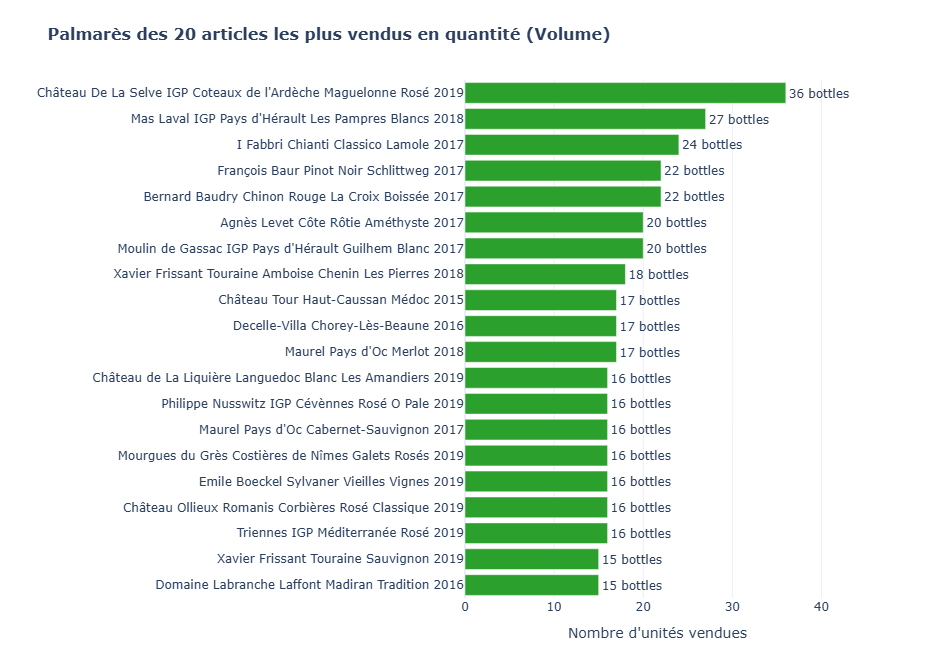

In [30]:
#==========================================================================================================
# PALMARÈS : Top 20 des articles les plus vendus (volume)
# ======================================================================================================== 

# 1. Enregistrement de df_final dans DuckDB
duckdb.register('df_duck_vol', df_final)

# 2. Requête SQL pour extraire le Top 20 en volume, puis inversion avec .iloc[::-1] pour Plotly
df_top20_vol_plot = duckdb.query("""
    SELECT product_id, post_title, price, total_sales, CA
    FROM df_duck_vol
    ORDER BY total_sales DESC
    LIMIT 20
""").df().iloc[::-1]

# 3. Création du graphique en barres horizontal interactif avec Plotly
fig_vol = px.bar(
    data_frame=df_top20_vol_plot,
    y="post_title", 
    x="total_sales",
    orientation="h",
    title="<b>Palmarès des 20 articles les plus vendus en quantité (Volume)</b>",
    labels={"post_title": "Produit", "total_sales": "Quantité totale vendue (unités)"},
    text="total_sales"
)

# 5. Amélioration du design
fig_vol.update_traces(
    texttemplate='%{text:,.0f} bottles', 
    textposition='outside',
    marker_color='#2ca02c' 
)

fig_vol.update_layout(
    xaxis_title="Nombre d'unités vendues",
    yaxis_title="",
    title_font_size=16,
    height=650,
    xaxis=dict(range=[0, df_top20_vol_plot['total_sales'].max() * 1.2]),
    margin=dict(l=150, r=100, t=80, b=50),
    template="plotly_white"
)

# export graphique
os.makedirs("Graphiques", exist_ok=True)
fig_vol.write_image("Graphiques/top20_volume.png", scale=2)


# Affichage du graphique interactif
fig_vol.show()

<div style="border: 1.5px solid black; padding: 10px;">
<h4  style="color:Blue;"> Analyse du TOP 20 du CA en volume : </h4>
<p> Le palmarès des 20 articles les plus vendus en quantité (premier écran) :</p>
<ul>
    <li> <b> Le leader des volumes : </b> C'est le Château De La Selve IGP Coteaux de l'Ardèche Maguelonne Rosé 2019 qui arrive en tête avec 36 bouteilles vendues.</li>
    <li> <b>Un profil de produits radicalement différent : </b> Contrairement au palmarès du chiffre d'affaires en valeur dominé par des grands crus et champagnes onéreux (Egly-Ouriet à plus de 2 000 €), ce classement met en avant des vins de pays et des références accessibles (IGP Pays d'Hérault, Chianti Classico, Côtes du Rhône, rosés).</li>
     <li> <b>Des volumes modestes mais réguliers : </b> Même le meilleur vendeur ne dépasse pas 36 unités, et le bas du Top 20 tourne autour de 15 bouteilles. Cela montre un catalogue diffus, sans produit de grande consommation de masse, mais avec des volumes homogènes sur les références intermédiaires. </li>
</ul>

<div style="border: 1.5px solid black; padding: 10px;">
<h4  style="color:Blue;"> Comparaison CA  valeur vs Volume :</h4>

 <p> L'analyse croisée démontre la dualité classique du e-commerce vinicole : d'un côté, les volumes sont portés par des bouteilles grand public et abordables (les best-sellers en quantité) ; de l'autre, la valeur (le chiffre d'affaires) est générée par les flacons de prestige à forte marge unitaire.</p>

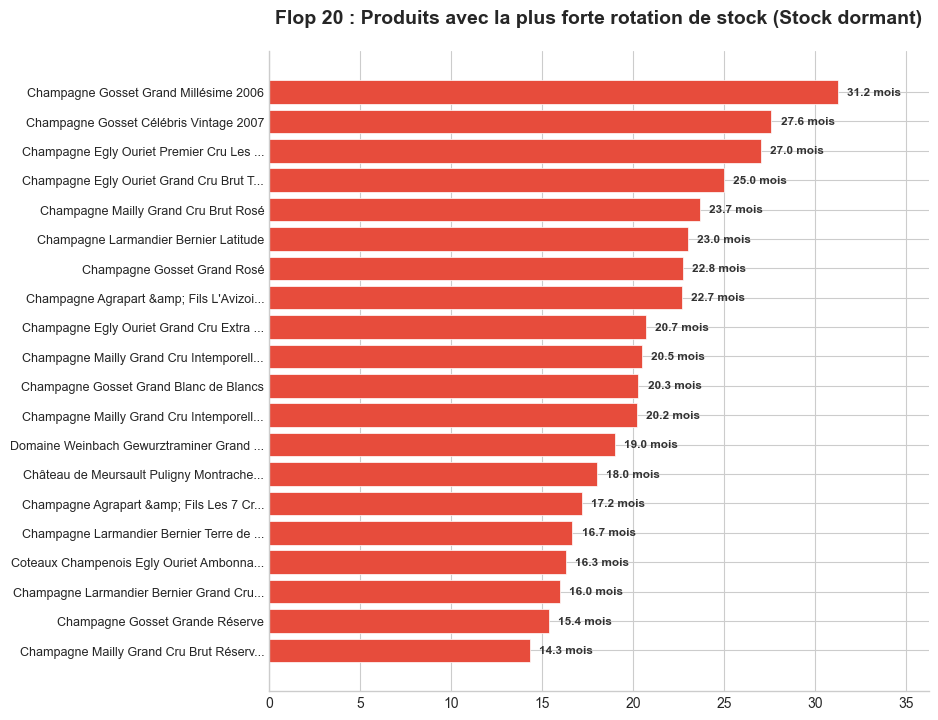

- VALEUR TOTALE DU STOCK IMMOBILISE
📦 Volume total en stock : 17,803 bouteilles
💰 Valeur totale du stock immobilisé : 298,540.07 €

 - VALEUR DU STOCK IMMOBILISE FLOP20
📦 Volume total en stock du flop20: 2,052 bouteilles  soit 11.53 % du volume total.
💰 Valeur totale du stock immobilisé du flop20 : 87,108.25 € soit 29.18 % de la valeur totale.


In [31]:
# =======================================================================================================
# ANALYSE DES STOCKS : ROTATION & VALORISATION FINANCIÈRE (VERSION V2 CORRIGÉE)
# Extraction au 31/10 ; total_sales = ventes du 01/10 au 31/10 (énoncé de la mission). Rotation (mois) = stock / ventes du mois. »
# ========================================================================================================

df_final = duckdb.query("""
    SELECT *,
        -- Gestion propre de la rotation (mois) en évitant les divisions par zéro
        CASE 
            WHEN total_sales > 0 THEN ROUND(CAST(stock_quantity AS DOUBLE) / total_sales, 2)
            ELSE 0 
        END AS rotation_stock,
        
        -- Valorisation financière du stock en euros
        (stock_quantity * purchase_price) AS valorisation_stock_euros
    FROM df_final
""").df()

# 1. Enregistrement de df_final dans DuckDB
duckdb.register('df_stock', df_final)

# 2. Calcul de la rotation de stock et extraction du Flop 20 via DuckDB
df_flop20_stock = duckdb.query("""
    SELECT 
        product_id,
        post_title,
        price,
        purchase_price,
        stock_quantity,
        total_sales,
        rotation_stock,
        valorisation_stock_euros        
    FROM df_stock
    ORDER BY rotation_stock DESC NULLS LAST
    LIMIT 20
""").df()

# Remplacement des valeurs nulles restantes par 0 pour le graphique
df_flop20_stock['rotation_stock'] = df_flop20_stock['rotation_stock'].fillna(0)

# 3. Création du graphique Matplotlib pour le Flop 20
fig, ax = plt.subplots(figsize=(12, 8))

# Troncature propre des noms de produits
raw_names = df_flop20_stock['post_title'].astype(str).values
clean_names = [n.replace('-', ' ')[:38] + '...' if len(n) > 38 else n.replace('-', ' ') for n in raw_names]

# Création des barres horizontales
bars = ax.barh(np.arange(len(clean_names)), df_flop20_stock['rotation_stock'], color='#e74c3c', edgecolor='white', linewidth=0.5)

# Application explicite des noms sur l'axe Y
ax.set_yticks(np.arange(len(clean_names)))
ax.set_yticklabels(clean_names, fontsize=9)

# Ajout des valeurs numériques au bout des barres
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.5, 
            bar.get_y() + bar.get_height()/2, 
            f'{width:,.1f} mois', 
            va='center', ha='left', 
            fontsize=8.5, fontweight='bold', color='#333333')

# Esthétique des axes et du titre
ax.set_title('Flop 20 : Produits avec la plus forte rotation de stock (Stock dormant)', fontsize=14, pad=20, fontweight='bold')

# Nettoyage des bordures
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# Marge à droite pour les étiquettes et inversion pour avoir le pire en haut
ax.set_xlim(0, df_flop20_stock['rotation_stock'].max() + 5)
ax.invert_yaxis()

# Marge de gauche élargie pour les noms longs
plt.subplots_adjust(left=0.35, right=0.90, top=0.90, bottom=0.1)

# Export du graphique
plt.savefig("Graphiques/rotation_stock.png", dpi=300, bbox_inches="tight")

# Affichage
plt.show()

# --------------------------------------------------------------------------------
# 4. VALORISATION FINANCIÈRE ET VOLUMÉTRIQUE GLOBALE DES STOCKS (VIA DUCKDB)
#---------------------------------------------------------------------------------
df_res_stocks = duckdb.sql("""
    SELECT 
        SUM(stock_quantity) AS volume_total,
        SUM(stock_quantity * purchase_price) AS valeur_totale
    FROM df_stock
""").df()

# Volume et valeur du stock global
volume_total_stock = df_res_stocks['volume_total'].iloc[0] if not pd.isna(df_res_stocks['volume_total'].iloc[0]) else 0
valeur_totale_stock = df_res_stocks['valeur_totale'].iloc[0] if not pd.isna(df_res_stocks['valeur_totale'].iloc[0]) else 0

# Affichage propre des indicateurs clés de stock
print("- VALEUR TOTALE DU STOCK IMMOBILISE")
print(f"📦 Volume total en stock : {volume_total_stock:,.0f} bouteilles")
print(f"💰 Valeur totale du stock immobilisé : {valeur_totale_stock:,.2f} €")

# Volume et valeur du stock du Flop
volume_total_stock_flop20 = df_flop20_stock['stock_quantity'].sum()
valeur_totale_stock_flop20 = df_flop20_stock['valorisation_stock_euros'].sum()


# Affichage propre des indicateurs clés de stock
print("\n - VALEUR DU STOCK IMMOBILISE FLOP20")
print(f"📦 Volume total en stock du flop20: {volume_total_stock_flop20:,.0f} bouteilles  soit {(volume_total_stock_flop20 / volume_total_stock) * 100:.2f} % du volume total.")
print(f"💰 Valeur totale du stock immobilisé du flop20 : {valeur_totale_stock_flop20:,.2f} € soit {(valeur_totale_stock_flop20 / valeur_totale_stock) * 100:.2f} % de la valeur totale.")


<div style="border: 1.5px solid black; padding: 10px;">
<h4  style="color:Blue;"> Analyse valorisation des stocks:</h4>
<ul>
    <li> <b>Une immobilisation critique :  </b> Les produits en tête de ce classement affichent un stock immobilisé équivalant à plus de 31 mois de vente (soit près de trois ans d'autonomie avec le stock actuel).</li>
    <li> <b>Paradoxe des marques :</b> La catégorie Champagnes domine le flop 20   </li>
    <li> <b>Trésorerie immobilisée : </b> Un stock dormant de 17803 bouteilles pèse lourdement sur la santé financière de l'entreprise avec une valeur totale du stock immobilisé s'élevant à 298,540.07 €. </li>
    <li> <b>Piste d'optimisation : </b>Ce graphique met en lumière les produits qui nécessitent des actions commerciales urgentes (soldes ciblées, mises en avant, offres groupées ou déstockage) pour libérer du cash-flow et éviter l'obsolescence de produits d'exception. </li>
</ul>
</div>


 ANALYSE DES TAUX DE MARGE ET DE LA RENTABILITÉ (VIA DUCKDB)
• Taux de marge minimum global : -83.67%
• Taux de marge maximum global : 129.69%

--- Produits avec un taux de marge négatif (< 0) ---


,product_id,post_title,price,stock_quantity,stock_status,purchase_price,taux_marge
0,4355,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,12.65,97,instock,77.48,-83.67
1,6324,NaN,92.00,18,instock,99.00,-7.07
2,7196,NaN,31.00,55,instock,31.20,-0.64
3,4864,NaN,8.30,0,outofstock,9.99,-16.92



• Le taux de marge minimum (positif) est de : 55.3974%
• Le taux de marge maximum (positif) est de : 129.6950% 


• Taux de marge moyen par catégorie de produit : 
    product_type  taux_marge
0         Cognac      118.78
1         Whisky      118.09
2            Gin      109.79
3            NaN       94.09
4            Vin       93.79
5      Champagne       67.95
6  Huile d'olive       60.07


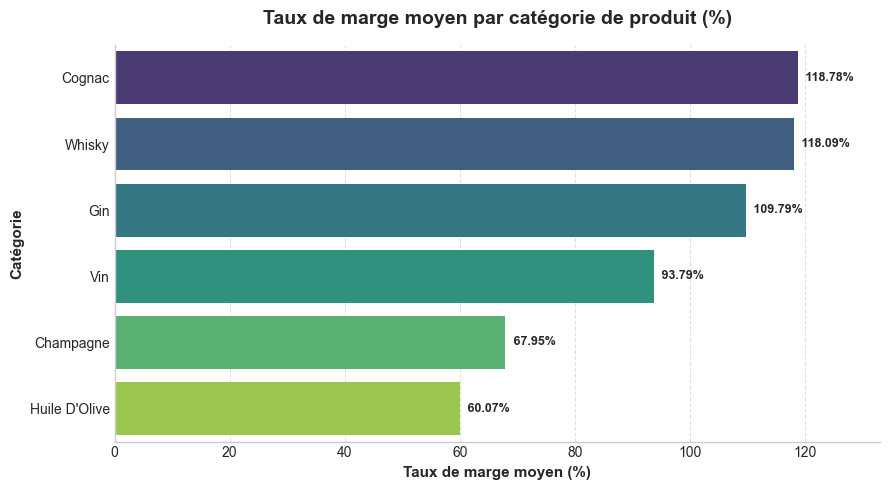

In [32]:
# ========================================================================================================
# ÉTAPE 7 - ANALYSE DE LA RENTABILITÉ : TAUX DE MARGE (VERSION TABLEAUX)
# ========================================================================================================


print("=" * 60)
print(" ANALYSE DES TAUX DE MARGE ET DE LA RENTABILITÉ (VIA DUCKDB)")
print("=" * 60)

# 1. Enregistrement de df_final dans DuckDB et calcul des champs HT et taux de marge
duckdb.register('df_rentabilite', df_final)

# Enrichissement global via DuckDB
df_calc = duckdb.query("""
    SELECT 
        *,
        (price / 1.2) AS prix_ht,
        (purchase_price / 1.2) AS Prix_achat_HT,
        (((price / 1.2) - (purchase_price / 1.2)) / (purchase_price / 1.2)) * 100 AS taux_marge
    FROM df_rentabilite
""").df()

# Mise à jour de df_final avec ces colonnes pour la suite du notebook si besoin
df_final = df_calc
duckdb.register('df_rentabilite', df_final)

#--------------------------------
# STAT SUR MARGE GLOBALE
# ------------------------------

# Affichage des min/max globaux via DuckDB
# Affichage des min/max globaux via .df() pour éviter l'erreur de relation
df_min_max = duckdb.query("""
    SELECT MIN(taux_marge) AS min_marge, MAX(taux_marge) AS max_marge 
    FROM df_rentabilite
""").df()

min_val = df_min_max['min_marge'].iloc[0]
max_val = df_min_max['max_marge'].iloc[0]

print(f'• Taux de marge minimum global : {min_val:.2f}%')
print(f'• Taux de marge maximum global : {max_val:.2f}%')

# 2. Tableau des anomalies (marge négative) via DuckDB
print('\n--- Produits avec un taux de marge négatif (< 0) ---')
anomalies_marge = duckdb.query("""
    SELECT product_id, post_title, price, stock_quantity, stock_status, purchase_price, taux_marge
    FROM df_rentabilite
    WHERE taux_marge < 0
""").df()

if not anomalies_marge.empty:
    display(anomalies_marge.reset_index(drop=True))
else:
    print('Aucun produit avec une marge négative.')

#--------------------------------
# STAT SUR MARGE POSITIVE
# ------------------------------
 #SELECT MIN(taux_marge) AS min_pos, MAX(taux_marge) AS max_pos 
# Statistiques sur la marge positive via .df()
df_min_max_pos = duckdb.query("""
    SELECT *
    FROM df_rentabilite 
    WHERE taux_marge > 0
""").df()

min_marge_positive = df_min_max_pos['taux_marge'].min()
max_marge_positive = df_min_max_pos['taux_marge'].max()

print(f"\n• Le taux de marge minimum (positif) est de : {min_marge_positive:.4f}%")
print(f"• Le taux de marge maximum (positif) est de : {max_marge_positive:.4f}% \n")

# 4. Agrégation par catégorie (Moyenne du taux de marge pour les marges > 0)
df_marge_par_type = duckdb.query("""
    SELECT product_type, AVG(taux_marge) AS taux_marge
    FROM df_rentabilite
    WHERE taux_marge > 0
    GROUP BY product_type
    ORDER BY taux_marge DESC
""").df()

print("\n• Taux de marge moyen par catégorie de produit : ")
print(df_marge_par_type)
print("=" * 60)


#-----------------------------------------
# Visualisation graphique (Seaborn)
#-----------------------------------------

# Une seule ligne par catégorie (évite les doublons), triée par taux décroissant
df_plot = (
    df_marge_par_type
    .assign(product_type=lambda d: d['product_type'].str.strip().str.title())
    .groupby('product_type', as_index=False)['taux_marge']
    .mean()
    .sort_values('taux_marge', ascending=False)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    x='taux_marge',
    y='product_type',
    data=df_plot,
    hue='product_type',
    palette='viridis',
    legend=False,
    order=df_plot['product_type'],
    ax=ax,
)

ax.set_title(
    'Taux de marge moyen par catégorie de produit (%)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
ax.set_xlabel('Taux de marge moyen (%)', fontsize=11, fontweight='bold')
ax.set_ylabel('Catégorie', fontsize=11, fontweight='bold')
ax.grid(axis='x', linestyle='--', alpha=0.6)
ax.set_axisbelow(True)
sns.despine(top=True, right=True)

# Labels lus directement sur la largeur réelle de chaque barre
for container in ax.containers:
    ax.bar_label(container, fmt=' %.2f%%', padding=3, fontsize=9, fontweight='bold')

ax.set_xlim(0, df_plot['taux_marge'].max() * 1.12)

plt.tight_layout()

# Export graphique
plt.savefig('Graphiques/marge_cat_produit.png', dpi=300, bbox_inches='tight')

# Export en fichier Excel
anomalies_marge.to_excel('Export_Excel/anomalies_marge.xlsx', index=False)

# Affichage
plt.show()


<div style="border: 1.5px solid black; padding: 10px;">
<h4  style="color:Blue;"> Analyse de la marge commerciale </h4>

<ul>
<li> <b>Les champions de la marge : </b> Le Cognac (118,78 %) et le Whisky (118,09 %) et le Gin (109,79 %) génèrent une forte rentabilité relative par rapport à leur prix d'achat. </li>
<li> <b> Les dernier de la marge : </b> le Champagne (67,95 %) et l'Huile d'olive (60,07 %) affichent les taux de marge moyens les plus faibles du catalogue.</li>
<li> <b>Une anomalie critique : </b> 4 produits dont le prix de vente est inférieur au prix d'achat, ce qui est incohérent avec la logique métier (probablement des erreurs de saisie dans le ERP/catalogue où le prix de vente est erroné ou inversé).</li>
</ul>
</div>

✅ Matrice de corrélation générée et sauvegardée avec succès dans le dossier Graphiques 



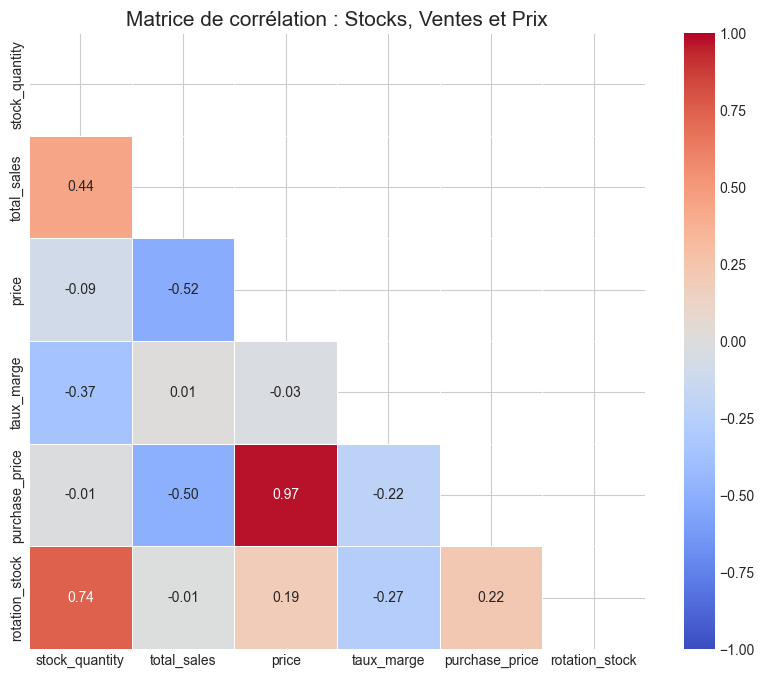

In [33]:
#Que peut-on conclure des corrélations ?
# ========================================================================================================
# ANALYSE DES CORRÉLATIONS (HEATMAP TRIANGULAIRE) avec le dataframe commercial
# ========================================================================================================

# 1. Sélection des variables clés pour la corrélation
cols_corr = ['stock_quantity','total_sales','price','taux_marge','purchase_price','rotation_stock']
df_corr = df_final[cols_corr].corr()

# 2. Création du masque pour masquer la partie supérieure (triangulaire)
mask = np.triu(np.ones_like(df_corr, dtype=bool))

# 3. Configuration de la figure
plt.figure(figsize=(10, 8))

# 4. Création de la heatmap
sns.heatmap(df_corr, 
            mask=mask, 
            annot=True, 
            fmt=".2f", 
            cmap='coolwarm', 
            vmin=-1, vmax=1, 
            center=0,
            square=True, 
            linewidths=.5)

plt.title('Matrice de corrélation : Stocks, Ventes et Prix', fontsize=15)

#Export graphique
plt.savefig("Graphiques/corr_stock_ventes_prix.png", dpi=300, bbox_inches="tight")

print(f"✅ Matrice de corrélation générée et sauvegardée avec succès dans le dossier Graphiques \n")

# Affichage
plt.show()


<div style="border: 1.5px solid black; padding: 10px;">
    <h4  style="color:Blue;">Analyse des corrélations :</h4>   

<h5> <b> 1. Corrélations fortes et logiques : </b></h5>
<ul>    
<li> <b> Corrélation quasi parfaite et évidente entre le prix et le prix d'achat (0,97) :</b> C'est tout à fait logique, les prix de vente suivent mécaniquement les coûts d'achat (structure tarifaire cohérente).</li>
<li> <b> Corrélation forte entre la quantité en stock et la rotation du stock (0,74) :</b> Un stock important pèse directement sur le temps de rotation (les produits qui dorment le plus sont logiquement ceux qui s'accumulent en stock).</li>
</ul>

<h5> <b>2. Corrélations modérées : </b></h5>
<ul>
   <li> <b> Une corrélation positive modérée entre ventes et stock (0,44) :</b>  montre que les produits qui se vendent le plus ont aussi tendance à avoir des volumes de stock associés pour suivre la demande, sans pour autant créer de blocage massif.</li>
<li> <b> Corrélation négative modérée entre le prix et les ventes (-0,52) : </b>Plus un produit est cher, moins il se vend en volume. C'est le reflet classique de l'élasticité-prix (les bouteilles haut de gamme ou chères tournent moins vite).</li>
</ul>   

<h5> <b> 3. Absence de corrélation notable :</b></h5>
<ul>
   <li> <b> Taux de marge et autres variables :</b>  Le taux de marge présente des coefficients proches de zéro avec la plupart des indicateurs ce qui signifie que la rentabilité relative ne dépend pas du volume vendu</li>  
</ul>


<h5> <b>  Verdict: <b>  </h5>
<p> Cette matrice valide la cohérence globale du modèle économique de BottleNeck : un positionnement haut de gamme qui freine les volumes unitaires mais s'appuie sur des prix d'achat et de vente fortement corrélés, tout en mettant en garde contre l'alourdissement de la rotation pour les stocks les plus importants. /p>
</div>


In [34]:
# Infos df marge positive
print(f" --- Infos Dataframe global --- \n {df_final.info()}")
print(f" --- Infos Dataframe avec des marge positives --- \n {df_min_max_pos.info()}")


<class 'pandas.DataFrame'>
RangeIndex: 820 entries, 0 to 819
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   product_id                820 non-null    int64         
 1   price                     820 non-null    float64       
 2   stock_quantity            820 non-null    int64         
 3   stock_status              820 non-null    str           
 4   purchase_price            820 non-null    float64       
 5   onsale_web                820 non-null    int64         
 6   id_web                    733 non-null    str           
 7   virtual                   713 non-null    Int64         
 8   downloadable              713 non-null    Int64         
 9   rating_count              713 non-null    Int64         
 10  average_rating            713 non-null    float64       
 11  total_sales               713 non-null    float64       
 12  tax_status                713 non

In [35]:
#Mettre le dataset df_merge sur un fichier Excel
#Cette étape peut être utile pour partager le résultat du dataset obtenu avec les équipes.  

# 1. Création sécurisée du dossier de sortie
os.makedirs('Rapport', exist_ok=True)
# 2. Exportation des fichiers Excel
df_min_max_pos.to_excel('Rapport/dataframe_marge_positive_bottleneck.xlsx', index=False)

print("✅ Les fichiers ont été générés avec succès dans le dossier Rapport.")

✅ Les fichiers ont été générés avec succès dans le dossier Rapport.


In [36]:
#================================
# EXPORT DU DATAFRAME FINAL 
#================================

import pandas as pd
from openpyxl.styles import PatternFill, Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# 1. Définition d'un ordre logique pour les colonnes de df_final
nouvel_ordre_colonnes = [
    # --- Identification Principale ---
    'product_id', 'id_web', 'post_title',
    
    # --- Tarification & Rentabilité ---
    'price', 'prix_ht', 'purchase_price', 'Prix_achat_HT', 'taux_marge',
    
    # --- Gestion des Stocks ---
    'stock_status', 'stock_quantity', 'valorisation_stock_euros', 'rotation_stock',
    
    # --- Performance Commerciale & Web ---
    'onsale_web', 'total_sales', 'CA', 'rating_count', 'average_rating',
    
    # --- Audit & Détection d'anomalies (Outliers) ---
    'is_outlier', 'consensus_count', 'outlier_if', 'outlier_zscore', 'outlier_iqr',
    
    # --- Métadonnées Secondaires (déplacées à la fin) ---
    'product_type', 'post_type', 'post_date', 'post_modified', 
    'virtual', 'downloadable', 'tax_status'
]

# Sécurité : conserve uniquement les colonnes existantes et ajoute d'éventuelles colonnes non listées à la fin
colonnes_presentes = [col for col in nouvel_ordre_colonnes if col in df_final.columns]
colonnes_restantes = [col for col in df_final.columns if col not in colonnes_presentes]

df_final_ordonne = df_final[colonnes_presentes + colonnes_restantes].copy()

# --- ARRONDIS DES DÉCIMALES ---
colonnes_floats = df_final_ordonne.select_dtypes(include=['float64', 'float32']).columns
df_final_ordonne[colonnes_floats] = df_final_ordonne[colonnes_floats].round(2)

# 2. Export et stylisation avancée dans Excel
chemin_export = 'Rapport/dataframe_final_bottleneck.xlsx'

with pd.ExcelWriter(chemin_export, engine='openpyxl') as writer:
    df_final_ordonne.to_excel(writer, sheet_name='Données Finales', index=False)
    
    workbook = writer.book
    worksheet = writer.sheets['Données Finales']
    
    # Figer la première ligne (en-tête) lors du défilement
    worksheet.freeze_panes = 'A2'
    
    # Activer les filtres automatiques sur toute la plage de données
    worksheet.auto_filter.ref = worksheet.dimensions
    
    # --- STYLISATION DE L'EN-TÊTE ---
    # Fond bleu marine (#212E53), texte blanc en gras, centré
    header_fill = PatternFill(start_color="212E53", end_color="212E53", fill_type="solid")
    header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
    header_alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    
    thin_border = Border(
        left=Side(style='thin', color='DCDCDC'),
        right=Side(style='thin', color='DCDCDC'),
        top=Side(style='thin', color='DCDCDC'),
        bottom=Side(style='thin', color='DCDCDC')
    )
    
    # Appliquer le style sur la ligne d'en-tête
    for col_num in range(1, len(df_final_ordonne.columns) + 1):
        cell = worksheet.cell(row=1, column=col_num)
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = header_alignment
        cell.border = thin_border
        
    # --- AJUSTEMENT DES LARGEURS DE COLONNES ---
    for idx, col in enumerate(df_final_ordonne.columns, 1):
        valeurs_str = df_final_ordonne[col].dropna().astype(str)
        max_contenu = valeurs_str.map(len).max() if not valeurs_str.empty else 0
        
        longueur_max = max(max_contenu, len(str(col))) + 6
        col_letter = get_column_letter(idx)
        worksheet.column_dimensions[col_letter].width = min(longueur_max, 45)

print(f"✅ Le fichier a été généré avec succès dans le dossier : {chemin_export}")


✅ Le fichier a été généré avec succès dans le dossier : Rapport/dataframe_final_bottleneck.xlsx


In [37]:
chemin_export = 'Rapport/dataframe_final_bottleneck.xlsx'

In [38]:
#==========================================
# GENERATION DU RAPPORT D'ANALYSE FINAL (PDF + EXCEL)
#==========================================
import os
import importlib
import rapport_bottleneck
importlib.reload(rapport_bottleneck)          
from rapport_bottleneck import generer_rapport

# 1. Ajout du nom des produits aux anomalies ERP/Web
noms = df_final[["product_id", "post_title"]]
aw = df_anomalies_web.merge(noms, on="product_id", how="left")[
    ["product_id", "post_title", "price", "stock_quantity", "stock_status", "onsale_web", "erreur_type"]
]

# 2. Anomalies à lister dans le rapport (une section par type)
anomalies = {
    "Stock négatif": df_stock_negatif,
    "Prix négatif": df_prix_negatif,
    "Statut de stock incohérent": df_erreurs_sql,
    "Publiés en rupture": aw[aw["erreur_type"].str.startswith("Rupture")].reset_index(drop=True),
    "Stock non publié": aw[aw["erreur_type"].str.startswith("Stock dormant")].reset_index(drop=True),
    "Marge négative": anomalies_marge,
}

# 3. Graphiques à intégrer
graphiques = {
    "pareto_ca":    "Graphiques/CA_Pareto_Comparatif_DuckDB.png",
    "top20_ca":     "Graphiques/Top_20_CA_prix_vente.png",
    "top20_volume": "Graphiques/top20_volume.png",
    "rotation":     "Graphiques/rotation_stock.png",
    "marge":        "Graphiques/marge_cat_produit.png",
}

# 4. Vérification que les fichiers images existent
for cle, chemin in graphiques.items():
    if not os.path.exists(chemin):
        print(f"⚠️ Graphique manquant : {chemin}")

# 5. Génération du rapport (dossier Rapport/)
chemin_pdf, chemin_xlsx = generer_rapport(df_final, anomalies, graphiques)

print("PDF existe   :", os.path.exists(chemin_pdf), "->", os.path.abspath(chemin_pdf))
print("Excel existe :", os.path.exists(chemin_xlsx), "->", os.path.abspath(chemin_xlsx))

✅ Rapport PDF   : Rapport\rapport_sante_financiere.pdf
✅ Rapport Excel : Rapport\rapport_sante_financiere.xlsx
PDF existe   : True -> C:\Users\compt\Desktop\0_0_0_Foramation_Data_Analyst\1_Projets\Projet_N13_Pilotez un projet data augmenté avec l'IA et créez votre portfolio de professionnel\analyse_donnees_bottleneck\Rapport\rapport_sante_financiere.pdf
Excel existe : True -> C:\Users\compt\Desktop\0_0_0_Foramation_Data_Analyst\1_Projets\Projet_N13_Pilotez un projet data augmenté avec l'IA et créez votre portfolio de professionnel\analyse_donnees_bottleneck\Rapport\rapport_sante_financiere.xlsx
